# SIR Epidemic Model with ODE Solvers

**DSTT G5 Project**  
**Course:** Data Science Tools & Techniques  
**Course Code:** AM609L  
**Group 5 Members:**  Sanghakara Manwar (26-27-13) |
            Rohit Satpute     (26-27-14) |
            Shreya            (26-27-15) |
            Tanesh Devhare    (26-14-05) 

---

## Project Objectives

1. **Implement Euler and RK4 methods** for the SIR differential equations; study numerical error against step size.
2. **Fit β (transmission rate) and γ (recovery rate)** to real COVID-19 data by minimizing squared error (grid search).
3. **Estimate R₀** and explain "flattening the curve" through scenario analysis.
4. **Bonus:** Digitize and fit the 1905-06 Bombay plague data (historical validation).

---

## Table of Contents

1. [SIR Model & Numerical Methods](#section1)
2. [Numerical Error Analysis](#section2)
3. [Analytical Verification](#section3)
4. [COVID-19 India: Second Wave (Feb–Aug 2021)](#section4)
5. [COVID-19 Japan: Summer Wave (Jul–Oct 2022)](#section5)
6. [Comparative Analysis: India vs Japan](#section6)
7. [Flattening the Curve: Scenario Analysis](#section7)
8. [Bonus: Bombay Plague 1905–06](#section8)
9. [Conclusions](#section9)

<a id='section1'></a>
# 1. SIR Model & Numerical Methods

## 1.1 Model Equations

The classic SIR model divides a population of size $N$ into three compartments:

$$
\begin{aligned}
\frac{dS}{dt} &= -\beta \frac{S I}{N} \\
\frac{dI}{dt} &= \beta \frac{S I}{N} - \gamma I \\
\frac{dR}{dt} &= \gamma I
\end{aligned}
$$

where:
- $S(t)$ = Susceptible individuals
- $I(t)$ = Infectious individuals
- $R(t)$ = Recovered/Removed individuals
- $\beta$ = Transmission rate (per day)
- $\gamma$ = Recovery rate (per day)
- $R_0 = \beta/\gamma$ = Basic reproduction number

## 1.2 Numerical Methods Implemented

- **Euler Method** (1st order): $y_{n+1} = y_n + h f(t_n, y_n)$
- **Runge-Kutta 4th Order (RK4)** (4th order): Standard 4-stage formulation
- **Reference Solution**: SciPy's `solve_ivp` with DOP853 method (rtol=1e-12, atol=1e-14)

## 1.3 Model Parameters (Synthetic Test Case)

- Total population $N = 1000$
- $\beta = 0.3$, $\gamma = 0.1$ $\rightarrow$ $R_0 = 3.0$
- Initial: $S_0 = 990$, $I_0 = 10$, $R_0 = 0$
- Time span: $t \in [0, 160]$ days

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from matplotlib.ticker import LogFormatterSciNotation
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit



In [2]:
# Model parameters 
N = 37061003
beta = 0.095
gamma = 0.0196
S0, I0, R0 = 26303393, 185837, 10571773
y0 = np.array([S0, I0, R0])
t_start, t_end = 0, 212

def sir_model(t, y):
    S, I, R = y
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    return np.array([dSdt, dIdt, dRdt])

def euler_method(f, y0, t):
    h = t[1] - t[0]
    n = len(t)
    y = np.zeros((n, len(y0)))
    y[0] = y0
    for i in range(n - 1):
        y[i + 1] = y[i] + h * f(t[i], y[i])
    return y

def rk4_method(f, y0, t):
    h = t[1] - t[0]
    n = len(t)
    y = np.zeros((n, len(y0)))
    y[0] = y0
    for i in range(n - 1):
        k1 = f(t[i], y[i])
        k2 = f(t[i] + h/2, y[i] + h*k1/2)
        k3 = f(t[i] + h/2, y[i] + h*k2/2)
        k4 = f(t[i] + h, y[i] + h*k3)
        y[i + 1] = y[i] + (h/6) * (k1 + 2*k2 + 2*k3 + k4)
    return y

# Reference solution
ref_sol = solve_ivp(sir_model, [t_start, t_end], y0,
                  method='DOP853', rtol=1e-12, atol=1e-14, dense_output=True)
t_ref = np.linspace(t_start, t_end, 1000)
y_ref = ref_sol.sol(t_ref)

print("Reference solution computed successfully.")
print(f"Time points: {len(t_ref)}, Final S,I,R: {y_ref[:, -1]}")

Reference solution computed successfully.
Time points: 1000, Final S,I,R: [ 1642529.43417716  3640072.10389776 31778401.46192508]


<a id='section2'></a>
# 2. Numerical Error Analysis

We compute the maximum absolute error across all three compartments (S, I, R) for a range of step sizes $h$, comparing against the high-accuracy reference solution.

In [3]:
# ERROR vs STEP SIZE STUDY

step_numbers = [40, 80, 160, 320, 640, 1280]
step_sizes = []
error_euler = []
error_rk4 = []

finest_euler = finest_rk4 = finest_time = None

for n_steps in step_numbers:
    h = (t_end - t_start) / n_steps
    t = np.linspace(t_start, t_end, n_steps + 1)
    
    y_euler = euler_method(sir_model, y0, t)
    y_rk4 = rk4_method(sir_model, y0, t)
    
    y_exact = ref_sol.sol(t).T
    
    euler_err = np.max(np.abs(y_euler - y_exact))
    rk4_err = np.max(np.abs(y_rk4 - y_exact))
    
    step_sizes.append(h)
    error_euler.append(euler_err)
    error_rk4.append(rk4_err)
    
    if n_steps == max(step_numbers):
        finest_euler, finest_rk4, finest_time = y_euler, y_rk4, t

step_sizes = np.array(step_sizes)
error_euler = np.array(error_euler)
error_rk4 = np.array(error_rk4)

print("NUMERICAL ERROR COMPARISON")
print("-" * 65)
print(f"{'Step Size':<15} {'Euler Error':<22} {'RK4 Error':<22}")
print("-" * 65)
for i in range(len(step_sizes)):
    print(f"{step_sizes[i]:<15.5f} {error_euler[i]:<22.8e} {error_rk4[i]:<22.8e}")

NUMERICAL ERROR COMPARISON
-----------------------------------------------------------------
Step Size       Euler Error            RK4 Error             
-----------------------------------------------------------------
5.30000         2.13063031e+06         3.68728332e+02        
2.65000         1.07478062e+06         2.52156231e+01        
1.32500         5.39181873e+05         1.64988620e+00        
0.66250         2.69877633e+05         1.05476242e-01        
0.33125         1.35007614e+05         6.67182915e-03        
0.16562         6.75181186e+04         4.29389998e-04        


In [4]:

# EXPERIMENTAL ORDER OF CONVERGENCE
# Fit log(error) vs log(step size) to estimate convergence order

euler_order = np.polyfit(np.log(step_sizes), np.log(error_euler), 1)[0]
rk4_order = np.polyfit(np.log(step_sizes), np.log(error_rk4), 1)[0]

print("\nEXPERIMENTAL ORDER OF CONVERGENCE")
print("-" * 50)
print(f"Euler Method : {euler_order:.4f}  (theoretical: 1.0)")
print(f"RK4 Method   : {rk4_order:.4f}  (theoretical: 4.0)")


EXPERIMENTAL ORDER OF CONVERGENCE
--------------------------------------------------
Euler Method : 0.9965  (theoretical: 1.0)
RK4 Method   : 3.9480  (theoretical: 4.0)


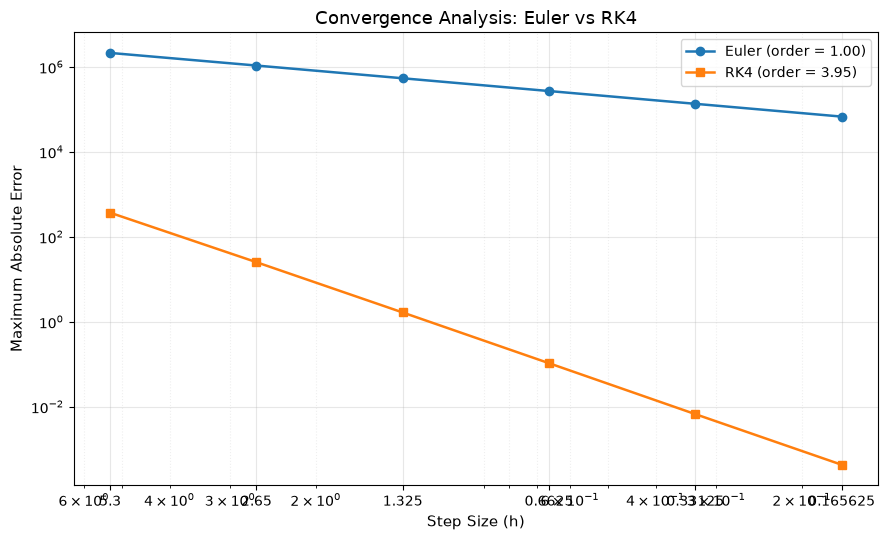

In [5]:
# PLOT: Error vs Step Size (Log-Log)

fig, ax = plt.subplots(figsize=(9, 5.5))

# Euler method
ax.loglog(
    step_sizes, error_euler,
    marker='o',
    linestyle='-',
    color='tab:blue',
    linewidth=1.8,
    markersize=6,
    label=f'Euler (order = {euler_order:.2f})'
)

# RK4 method
ax.loglog(
    step_sizes, error_rk4,
    marker='s',
    linestyle='-',
    color='tab:orange',
    linewidth=1.8,
    markersize=6,
    label=f'RK4 (order = {rk4_order:.2f})'
)


ax.set_xticks(step_sizes)
ax.set_xticklabels(
    [f'{h:g}' for h in step_sizes],
    fontsize=10
)


ax.yaxis.set_major_formatter(
    LogFormatterSciNotation()
)


ax.set_xlabel('Step Size (h)', fontsize=11)
ax.set_ylabel('Maximum Absolute Error', fontsize=11)
ax.set_title('Convergence Analysis: Euler vs RK4', fontsize=13)

ax.grid(True, which='major', linestyle='-', alpha=0.3)
ax.grid(True, which='minor', linestyle=':', alpha=0.2)

ax.legend(fontsize=10, frameon=True)

ax.invert_xaxis()

plt.tight_layout()
plt.show()


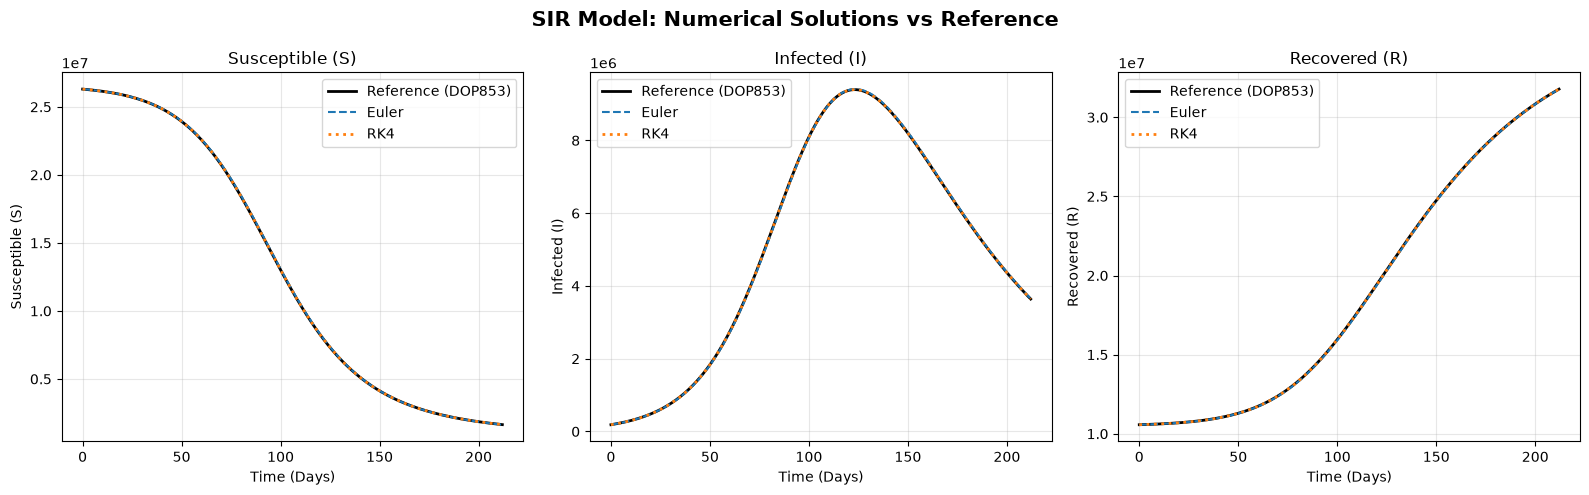

In [6]:
# PLOT: SIR Dynamics Comparison (Finest Step)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
labels = ['Susceptible (S)', 'Infected (I)', 'Recovered (R)']
colors_ref = 'k'
colors_euler = 'tab:blue'
colors_rk4 = 'tab:orange'

for i in range(3):

    axes[i].plot(
        t_ref, y_ref[i],
        color=colors_ref,
        linestyle='-',
        linewidth=2,
        label='Reference (DOP853)'
    )

    axes[i].plot(
        finest_time, finest_euler[:, i],
        color=colors_euler,
        linestyle='--',
        linewidth=1.5,
        label='Euler'
    )

    axes[i].plot(
        finest_time, finest_rk4[:, i],
        color=colors_rk4,
        linestyle=':',
        linewidth=2,
        label='RK4'
    )

    axes[i].set_title(labels[i])
    axes[i].set_xlabel('Time (Days)')
    axes[i].set_ylabel(labels[i])
    axes[i].grid(True, alpha=0.3)
    axes[i].legend()

fig.suptitle('SIR Model: Numerical Solutions vs Reference', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

<a id='section3'></a>
# 3. Analytical Verification

The SIR model has a known analytical invariant (conserved quantity):

$$
S + I - \frac{\gamma N}{\beta} \ln S = C
$$

where $C = S_0 + I_0 - \frac{\gamma N}{\beta} \ln S_0$ is constant along trajectories.

We verify how well each numerical method preserves this invariant.

In [7]:
# ANALYTICAL INVARIANT VERIFICATION

# Analytical constant C
C = S0 + I0 - (gamma * N / beta) * np.log(S0)

def sir_invariant(S, I):
    return S + I - (gamma * N / beta) * np.log(S)

def analytical_I(S):
    return S0 + I0 - S + (gamma * N / beta) * np.log(S / S0)


inv_euler = sir_invariant(finest_euler[:, 0], finest_euler[:, 1])
inv_rk4 = sir_invariant(finest_rk4[:, 0], finest_rk4[:, 1])

err_inv_euler = np.abs(inv_euler - C)
err_inv_rk4 = np.abs(inv_rk4 - C)

I_anal_euler = analytical_I(finest_euler[:, 0])
I_anal_rk4 = analytical_I(finest_rk4[:, 0])

err_I_euler = np.abs(finest_euler[:, 1] - I_anal_euler)
err_I_rk4 = np.abs(finest_rk4[:, 1] - I_anal_rk4)

print("ANALYTICAL VERIFICATION")
print("-" * 55)
print(f"Analytical constant C : {C:.8f}")
print(f"Euler I-error       : {np.max(err_I_euler):.8e}")
print(f"RK4 I-error         : {np.max(err_I_rk4):.8e}")
print(f"Euler max inv error : {np.max(err_inv_euler):.8e}")
print(f"RK4 max inv error   : {np.max(err_inv_rk4):.8e}")

ANALYTICAL VERIFICATION
-------------------------------------------------------
Analytical constant C : -104148888.78171085
Euler I-error       : 3.15925911e+04
RK4 I-error         : 2.28164718e-05
Euler max inv error : 3.15925911e+04
RK4 max inv error   : 2.28285789e-05


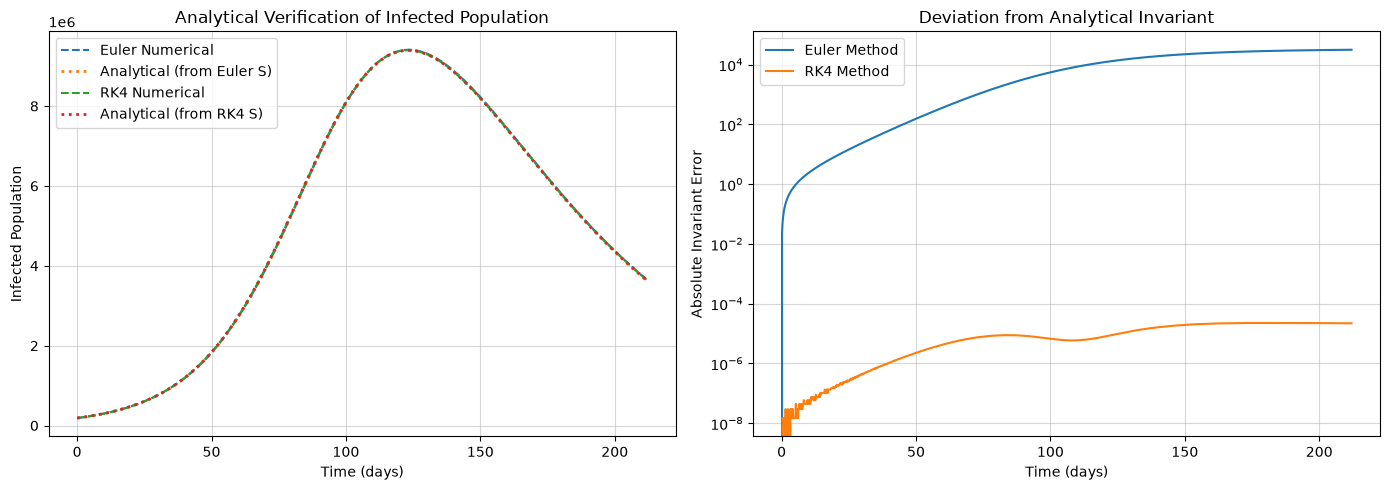

In [8]:
# PLOT: Analytical Verification

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Infected population vs analytical
axes[0].plot(finest_time, finest_euler[:, 1], '--', label='Euler Numerical', linewidth=1.5)
axes[0].plot(finest_time, I_anal_euler, ':', label='Analytical (from Euler S)', linewidth=2)
axes[0].plot(finest_time, finest_rk4[:, 1], '--', label='RK4 Numerical', linewidth=1.5)
axes[0].plot(finest_time, I_anal_rk4, ':', label='Analytical (from RK4 S)', linewidth=2)
axes[0].set_title('Analytical Verification of Infected Population')
axes[0].set_xlabel('Time (days)')
axes[0].set_ylabel('Infected Population')
axes[0].legend()
axes[0].grid(True, alpha=0.5)

# Invariant error over time
axes[1].semilogy(finest_time, err_inv_euler, label='Euler Method', linewidth=1.5)
axes[1].semilogy(finest_time, err_inv_rk4, label='RK4 Method', linewidth=1.5)
axes[1].set_title('Deviation from Analytical Invariant')
axes[1].set_xlabel('Time (days)')
axes[1].set_ylabel('Absolute Invariant Error')
axes[1].legend()
axes[1].grid(True, which='both', alpha=0.5)

plt.tight_layout()
plt.show()

<a id='section4'></a>
# 4. COVID-19 India: Second Wave (Feb–Aug 2021)

## 4.1 Data Description

- Source: `india_covid_cleaned.csv` (Our World in Data / JHU)
- Period: February 1 – August 31, 2021 (212 days)
- Peak daily cases: **414,188** (May 7, 2021)
- Total population: 1.425 billion

## 4.2 Estimating I(t) and R(t) from Case Data

Since only cumulative cases are reported, we estimate:
- Infectious period $D = 14$ days (standard assumption for COVID-19)
- $I(t) = \text{total\_cases}(t) - \text{total\_cases}(t-D)$
- $R(t) = \text{total\_cases}(t-D)$

## 4.3 Parameter Estimation: Grid Search

We minimize the normalized weekly squared error between observed and predicted new infections.
Two-stage grid search:
1. **Coarse**: $\beta \in [0.05, 1.0]$, $\gamma \in [0.03, 0.5]$, effective pop fraction $\in [0.01, 0.2]$
2. **Fine**: $\pm 5\%$ around coarse best

(2430, 10)
['country', 'date', 'total_cases', 'new_cases', 'total_deaths', 'population', 'new_deaths', 'reproduction_rate', 'people_fully_vaccinated', 'stringency_index']


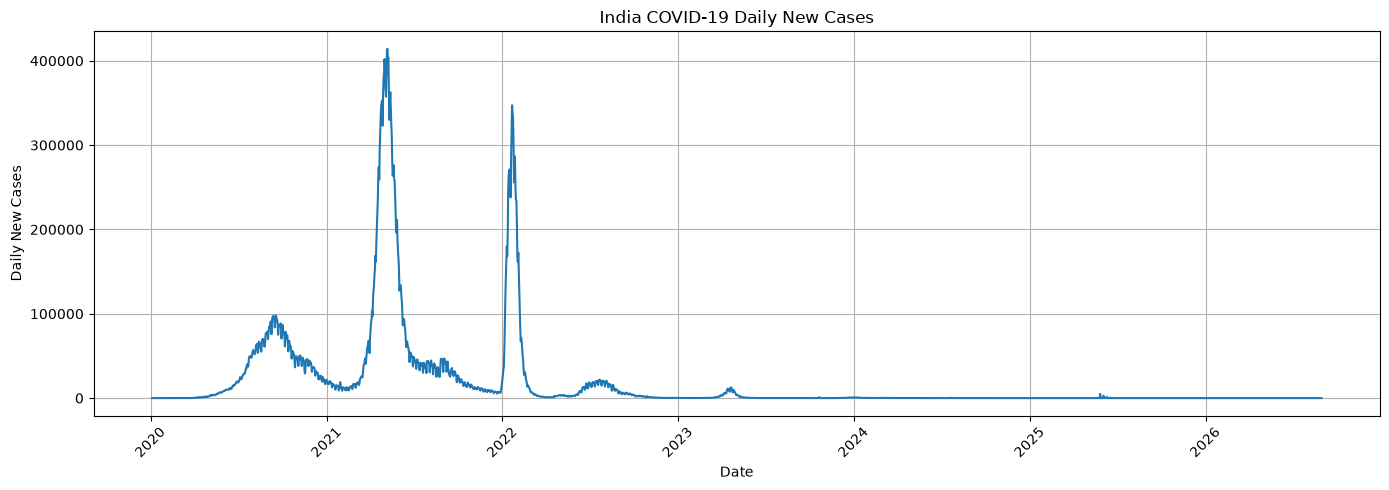

(212, 10)


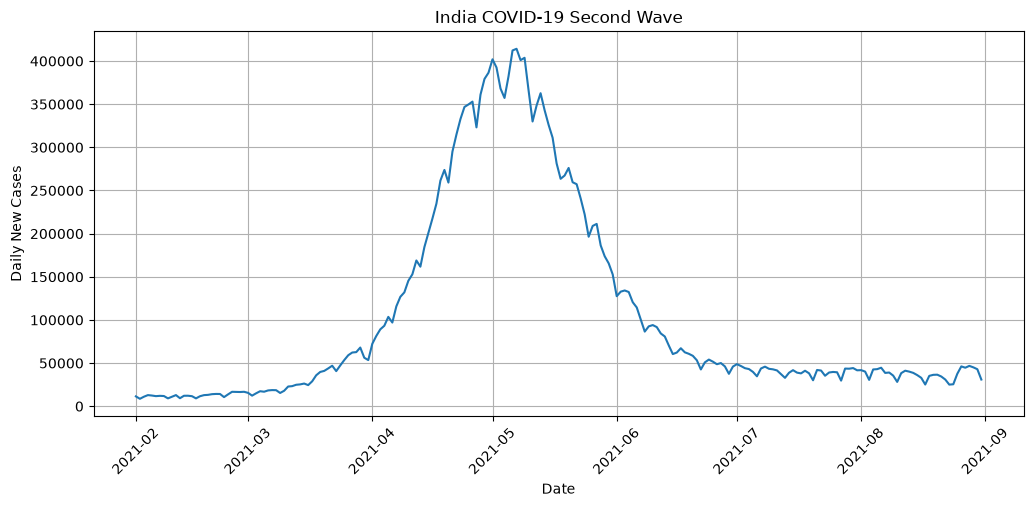

In [9]:
df = pd.read_csv("Data/india_covid_cleaned.csv")
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(df.shape)
print(df.columns.tolist())

# . WAVE SELECTION (Feb 2021 - Aug 2021)

plt.figure(figsize=(14, 5))

plt.plot(df['date'], df['new_cases'])

plt.xlabel('Date')
plt.ylabel('Daily New Cases')
plt.title('India COVID-19 Daily New Cases')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()
india_wave = df[(df['date'] >= '2021-02-01') &
                (df['date'] <= '2021-08-31')].copy()
print(india_wave.shape)

plt.figure(figsize=(12, 5))
plt.plot(india_wave['date'], india_wave['new_cases'])
plt.xlabel('Date'); plt.ylabel('Daily New Cases')
plt.title('India COVID-19 Second Wave')
plt.xticks(rotation=45); plt.grid(); plt.show()

In [10]:
# OBSERVED I AND R, AND INITIAL VALUES

D = 14                                
POP = df['population'].dropna().iloc[0]

df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

full = df.copy()
full['I'] = full['total_cases'] - full['total_cases'].shift(D)
full['R'] = full['total_cases'].shift(D)

wave = full[(full['date'] >= '2021-02-01') &
            (full['date'] <= '2021-08-31')].copy().reset_index(drop=True)
if wave[['I', 'R']].isna().any().any():
    raise ValueError("Not enough previous data to calculate I and R.")


dates = wave['date']
I_obs = wave['I'].values
R_obs = wave['R'].values
n_days = len(wave)

daily_cases = wave.iloc[1:].set_index('date')['new_cases']
observed_weekly = daily_cases.resample('W-SUN').sum()

I0 = I_obs[0]                            
R0_init = R_obs[0]                       
print(f"Days: {n_days} | I0 = {I0:,.0f} | R0_init = {R0_init:,.0f} | population = {POP:,.0f}")


def sir_rhs(y, beta, gamma, N):
    S, I, R = y
    new_inf = beta * S * I / N
    return np.array([-new_inf, new_inf - gamma * I, gamma * I])

def rk4_method(f, y0, t):
    h = t[1] - t[0]
    n = len(t)
    y = np.zeros((n, len(y0)))
    y[0] = y0
    for i in range(n - 1):
        k1 = f(t[i], y[i])
        k2 = f(t[i] + h/2, y[i] + h*k1/2)
        k3 = f(t[i] + h/2, y[i] + h*k2/2)
        k4 = f(t[i] + h,   y[i] + h*k3)
        y[i + 1] = y[i] + (h/6) * (k1 + 2*k2 + 2*k3 + k4)
    return y

t = np.arange(n_days, dtype=float)       

def simulate(beta, gamma, N_eff):  
    y0 = np.array([ N_eff - I0 - R0_init,I0,R0_init])
    f = lambda tt, y: sir_rhs(y, beta, gamma, N_eff)
    return rk4_method(f, y0, t)



# GRID SEARCH FOR beta, gamma AND frac (effective susceptible fraction)
# error = squared error on weekly new infections, each divided by its maximum

def grid_error(beta, gamma, frac):

    N_eff = frac * POP

    if N_eff <= I0 + R0_init:
        return np.inf

    sol = simulate(beta, gamma, N_eff)

    daily_pred = sol[:-1, 0] - sol[1:, 0]

    predicted_daily = pd.Series(daily_pred,index=dates.iloc[1:].values)

    predicted_weekly = predicted_daily.resample('W-SUN').sum()

    comparison = pd.concat([observed_weekly,predicted_weekly],axis=1).dropna()

    return np.sum(((comparison.iloc[:, 1] - comparison.iloc[:, 0])/ max(observed_weekly.max(), 1)) ** 2)

def grid_search(betas, gammas, fracs):
    best = (None, np.inf)
    err = np.full((len(betas), len(gammas), len(fracs)), np.inf)
    for i, b in enumerate(betas):
        for j, g in enumerate(gammas):
            for k, fr in enumerate(fracs):
                e = grid_error(b, g, fr)
                err[i, j, k] = e
                if e < best[1]:
                    best = ((b, g, fr), e)
    return best[0], best[1], err

t0 = time.time()
betas1  = np.linspace(0.05, 1.0, 25)
gammas1 = np.linspace(0.03, 0.5, 25)
fracs1  = np.array([0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.15, 0.2])
(b1, g1, f1), e1, _ = grid_search(betas1, gammas1, fracs1)
print(f"Coarse best: beta={b1:.3f}, gamma={g1:.3f}, frac={f1:.3f}, error={e1:.4f}  ({time.time()-t0:.0f}s)")

t0 = time.time()
betas2  = np.linspace(max(b1 - 0.05, 0.01), b1 + 0.05, 20)
gammas2 = np.linspace(max(g1 - 0.03, 0.01), g1 + 0.03, 20)
fracs2  = np.linspace(max(f1 * 0.6, 0.002), min(f1 * 1.4, 1.0), 10)
(beta_best, gamma_best, frac_best), e2, err_fine = grid_search(betas2, gammas2, fracs2)
N_eff = frac_best * POP
print(f"Fine best:   beta={beta_best:.4f}, gamma={gamma_best:.4f}, frac={frac_best:.4f}, error={e2:.4f}  ({time.time()-t0:.0f}s)")


#  BEST-FIT RESULTS AND INITIAL S, I, R

S0 = N_eff - I0 - R0_init

print("Best-fit parameters:")
print("Beta:", round(beta_best, 4))
print("Gamma:", round(gamma_best, 4))
print("Average infectious period:", round(1 / gamma_best, 2), "days")

print("Effective population:", round(N_eff))
print("Effective population fraction:", round(frac_best * 100, 2), "%")

print("\nInitial SIR values:")
print("S0:", round(S0))
print("I0:", round(I0))
print("R0_init:", round(R0_init))

print("\nPopulation check:", round(S0 + I0 + R0_init))
print("Expected population:", round(N_eff))


for name, val, grid in [('beta', beta_best, betas2), ('gamma', gamma_best, gammas2), ('frac', frac_best, fracs2)]:
    if np.isclose(val, grid.min()) or np.isclose(val, grid.max()):
        print(f"WARNING: {name} is at the fine-grid boundary.")
for name, val, grid in [('beta', b1, betas1), ('gamma', g1, gammas1), ('frac', f1, fracs1)]:
    if np.isclose(val, grid.min()) or np.isclose(val, grid.max()):
        print(f"WARNING: {name} is at the coarse-grid boundary.")


Days: 212 | I0 = 185,837 | R0_init = 10,571,773 | population = 1,425,423,209
Coarse best: beta=0.129, gamma=0.050, frac=0.030, error=0.6557  (36s)
Fine best:   beta=0.0950, gamma=0.0196, frac=0.0260, error=0.5000  (33s)
Best-fit parameters:
Beta: 0.095
Gamma: 0.0196
Average infectious period: 51.06 days
Effective population: 37061003
Effective population fraction: 2.6 %

Initial SIR values:
S0: 26303393
I0: 185837
R0_init: 10571773

Population check: 37061003
Expected population: 37061003


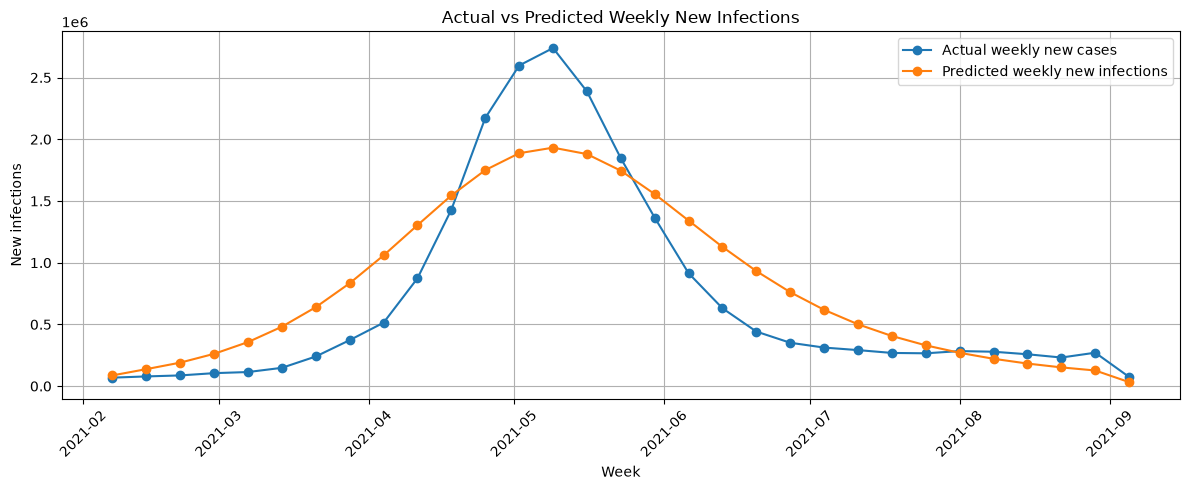

Weekly RMSE: 347831.3173372702
Weekly R2: 0.8112826151441004


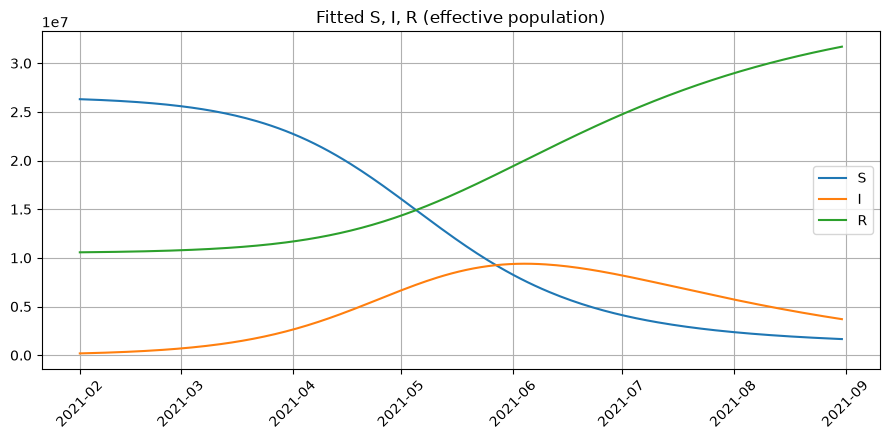

In [11]:
# PREDICTED VS ACTUAL

sol = simulate(beta_best, gamma_best, N_eff)

S_fit, I_fit, R_fit = sol[:, 0], sol[:, 1], sol[:, 2]


daily_pred = S_fit[:-1] - S_fit[1:]

predicted_daily = pd.Series(daily_pred,index=dates.iloc[1:].values)

predicted_weekly = predicted_daily.resample('W-SUN').sum()

comparison = pd.concat([observed_weekly.rename('Actual'),predicted_weekly.rename('Predicted')],
    axis=1).dropna()

plt.figure(figsize=(12, 5))
plt.plot(comparison.index, comparison['Actual'],marker='o', label='Actual weekly new cases')

plt.plot(comparison.index, comparison['Predicted'],marker='o', label='Predicted weekly new infections')

plt.xlabel('Week')
plt.ylabel('New infections')
plt.title('Actual vs Predicted Weekly New Infections')
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))

def r2(actual, predicted):
    return 1 - ( np.sum((actual - predicted) ** 2) /
        np.sum((actual - np.mean(actual)) ** 2))

actual_weekly = comparison['Actual'].values
pred_weekly = comparison['Predicted'].values

print("Weekly RMSE:", rmse(actual_weekly, pred_weekly))
print("Weekly R2:", r2(actual_weekly, pred_weekly))

# FITTED S, I, R CURVES 

plt.figure(figsize=(9, 4.5))
plt.plot(dates, S_fit, label='S'); plt.plot(dates, I_fit, label='I'); plt.plot(dates, R_fit, label='R')
plt.title('Fitted S, I, R (effective population)')
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<a id='section5'></a>
# 5. COVID-19 Japan: Summer Wave (Jul–Oct 2022)

## 5.1 Data Description

- Source: `japan_covid_cleaned.csv`
- Period: July 1 – October 31, 2022 (123 days)
- Peak daily cases: **326,090** (August 29, 2022)
- Total population: 125 million

## 5.2 Same Methodology as India

- Infectious period $D = 14$ days
- Two-stage grid search for $\beta$, $\gamma$, effective population fraction
- Weekly aggregation for noise reduction

(2473, 12)
['country', 'date', 'total_cases', 'new_cases', 'total_deaths', 'population', 'new_deaths', 'reproduction_rate', 'hosp_patients', 'icu_patients', 'people_fully_vaccinated', 'stringency_index']


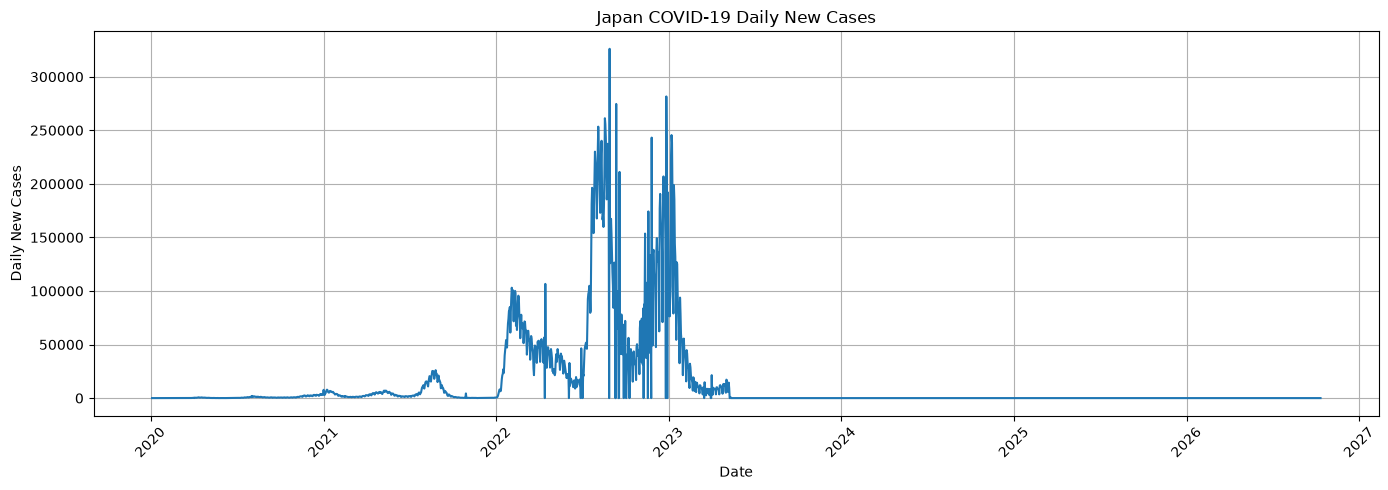

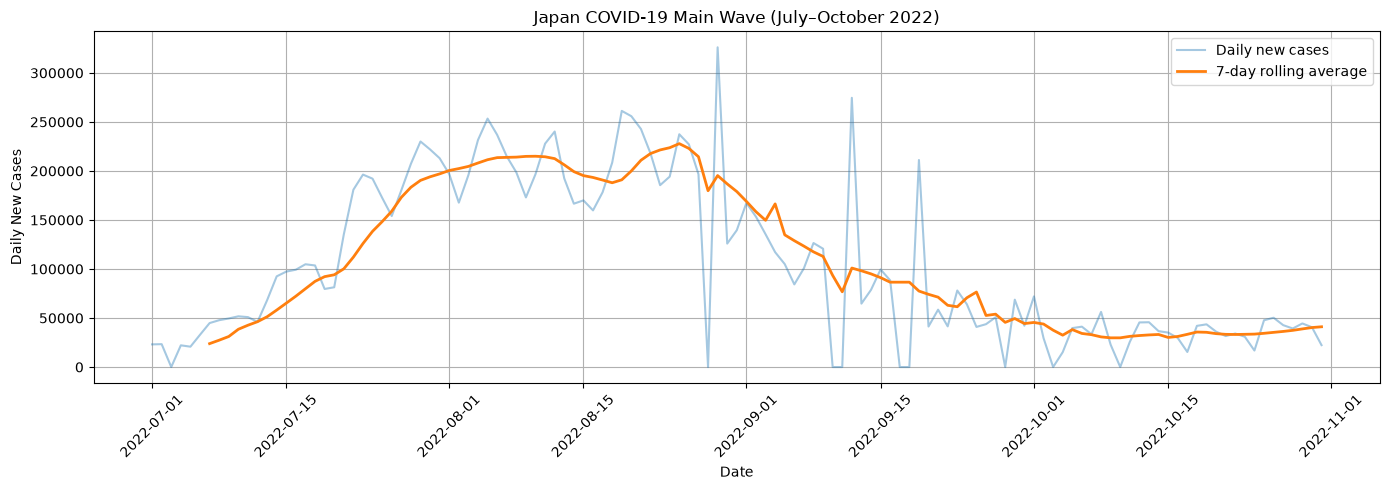

Shape: (123, 13)
Maximum daily cases: 326090.0
Peak date: 2022-08-29 00:00:00
Days: 123
I0 = 235,417
R0_init = 9,117,228
Population = 124,997,585
S0 = 115,644,940


In [12]:
df = pd.read_csv("Data/japan_covid_cleaned.csv")

df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(df.shape)
print(df.columns.tolist())

# Full Japan COVID-19 daily cases graph

plt.figure(figsize=(14, 5))

plt.plot(df['date'], df['new_cases'])

plt.xlabel('Date')
plt.ylabel('Daily New Cases')
plt.title('Japan COVID-19 Daily New Cases')

plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()


# JAPAN WAVE SELECTION

japan_wave = df[
    (df['date'] >= '2022-07-01') &
    (df['date'] <= '2022-10-31')].copy()

japan_wave['7_day_avg'] = (japan_wave['new_cases'].rolling(window=7).mean())

plt.figure(figsize=(14, 5))

plt.plot(
    japan_wave['date'],
    japan_wave['new_cases'],
    alpha=0.4,
    label='Daily new cases')

plt.plot(
    japan_wave['date'],
    japan_wave['7_day_avg'],
    linewidth=2,
    label='7-day rolling average')

plt.xlabel('Date')
plt.ylabel('Daily New Cases')
plt.title('Japan COVID-19 Main Wave (July–October 2022)')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

print("Shape:", japan_wave.shape)
print("Maximum daily cases:",
      japan_wave['new_cases'].max())
print("Peak date:",
      japan_wave.loc[japan_wave['new_cases'].idxmax(), 'date'])


# OBSERVED I AND R, AND INITIAL VALUES


D = 14

POP = df['population'].dropna().iloc[0]

df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

full = df.copy()
full['I'] = (full['total_cases'] -full['total_cases'].shift(D))
full['R'] = full['total_cases'].shift(D)

wave = full[(full['date'] >= '2022-07-01') &
    (full['date'] <= '2022-10-31')].copy().reset_index(drop=True)

if wave[['I', 'R']].isna().any().any():
    raise ValueError("Not enough previous data to calculate I and R.")

dates = wave['date']

I_obs = wave['I'].values
R_obs = wave['R'].values

n_days = len(wave)

daily_cases = wave.iloc[1:].set_index('date')['new_cases']

observed_weekly = daily_cases.resample('W-SUN').sum()

I0 = I_obs[0]
R0_init = R_obs[0]

print(f"Days: {n_days}")
print(f"I0 = {I0:,.0f}")
print(f"R0_init = {R0_init:,.0f}")
print(f"Population = {POP:,.0f}")

S0 = POP - I0 - R0_init
print(f"S0 = {S0:,.0f}")

In [13]:
def sir_rhs(y, beta, gamma, N):
    S, I, R = y
    new_inf = beta * S * I / N
    return np.array([-new_inf, new_inf - gamma * I, gamma * I])

def rk4_method(f, y0, t):
    h = t[1] - t[0]
    n = len(t)
    y = np.zeros((n, len(y0)))
    y[0] = y0
    for i in range(n - 1):
        k1 = f(t[i], y[i])
        k2 = f(t[i] + h/2, y[i] + h*k1/2)
        k3 = f(t[i] + h/2, y[i] + h*k2/2)
        k4 = f(t[i] + h,   y[i] + h*k3)
        y[i + 1] = y[i] + (h/6) * (k1 + 2*k2 + 2*k3 + k4)
    return y

t = np.arange(n_days, dtype=float)

def simulate(beta, gamma, N_eff):
    y0 = np.array([N_eff - I0 - R0_init,I0,R0_init])
    f = lambda tt, y: sir_rhs(y, beta, gamma, N_eff)
    return rk4_method(f, y0, t)

# GRID SEARCH FOR beta, gamma AND frac (effective susceptible fraction)
# error = squared error on weekly new infections, each divided by its maximum

def grid_error(beta, gamma, frac):

    N_eff = frac * POP

    if N_eff <= I0 + R0_init:
        return np.inf

    sol = simulate(beta, gamma, N_eff)

    daily_pred = sol[:-1, 0] - sol[1:, 0]

    predicted_daily = pd.Series(daily_pred,index=dates.iloc[1:].values)

    predicted_weekly = predicted_daily.resample('W-SUN').sum()

    comparison = pd.concat([observed_weekly,predicted_weekly],axis=1).dropna()

    return np.sum(((comparison.iloc[:, 1] - comparison.iloc[:, 0])/ max(observed_weekly.max(), 1)) ** 2)

def grid_search(betas, gammas, fracs):
    best = (None, np.inf)
    err = np.full((len(betas), len(gammas), len(fracs)), np.inf)
    for i, b in enumerate(betas):
        for j, g in enumerate(gammas):
            for k, fr in enumerate(fracs):
                e = grid_error(b, g, fr)
                err[i, j, k] = e
                if e < best[1]:
                    best = ((b, g, fr), e)
    return best[0], best[1], err

t0 = time.time()
betas1  = np.linspace(0.05, 1.0, 25)
gammas1 = np.linspace(0.03, 0.5, 25)
fracs1  = np.array([0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.15, 0.2])
(b1, g1, f1), e1, _ = grid_search(betas1, gammas1, fracs1)
print(f"Coarse best: beta={b1:.3f}, gamma={g1:.3f}, frac={f1:.3f}, error={e1:.4f}  ({time.time()-t0:.0f}s)")


t0 = time.time()
betas2  = np.linspace(max(b1 - 0.05, 0.01), b1 + 0.05, 20)
gammas2 = np.linspace(max(g1 - 0.03, 0.01), g1 + 0.03, 20)
fracs2  = np.linspace(max(f1 * 0.6, 0.002), min(f1 * 1.4, 1.0), 10)
(beta_best, gamma_best, frac_best), e2, err_fine = grid_search(betas2, gammas2, fracs2)
N_eff = frac_best * POP
print(f"Fine best:   beta={beta_best:.4f}, gamma={gamma_best:.4f}, frac={frac_best:.4f}, error={e2:.4f}  ({time.time()-t0:.0f}s)")


#  BEST-FIT RESULTS AND INITIAL S, I, R

S0 = N_eff - I0 - R0_init

print("Best-fit parameters:")
print("Beta:", round(beta_best, 4))
print("Gamma:", round(gamma_best, 4))
print("Average infectious period:", round(1 / gamma_best, 2), "days")

print("Effective population:", round(N_eff))
print("Effective population fraction:", round(frac_best * 100, 2), "%")

print("\nInitial SIR values:")
print("S0:", round(S0))
print("I0:", round(I0))
print("R0_init:", round(R0_init))

print("\nPopulation check:", round(S0 + I0 + R0_init))
print("Expected population:", round(N_eff))


for name, val, grid in [('beta', beta_best, betas2), ('gamma', gamma_best, gammas2), ('frac', frac_best, fracs2)]:
    if np.isclose(val, grid.min()) or np.isclose(val, grid.max()):
        print(f"WARNING: {name} is at the fine-grid boundary.")
for name, val, grid in [('beta', b1, betas1), ('gamma', g1, gammas1), ('frac', f1, fracs1)]:
    if np.isclose(val, grid.min()) or np.isclose(val, grid.max()):
        print(f"WARNING: {name} is at the coarse-grid boundary.")



Coarse best: beta=0.248, gamma=0.089, frac=0.200, error=0.2232  (14s)
Fine best:   beta=0.2663, gamma=0.1093, frac=0.2267, error=0.1123  (23s)
Best-fit parameters:
Beta: 0.2663
Gamma: 0.1093
Average infectious period: 9.15 days
Effective population: 28332786
Effective population fraction: 22.67 %

Initial SIR values:
S0: 18980141
I0: 235417
R0_init: 9117228

Population check: 28332786
Expected population: 28332786


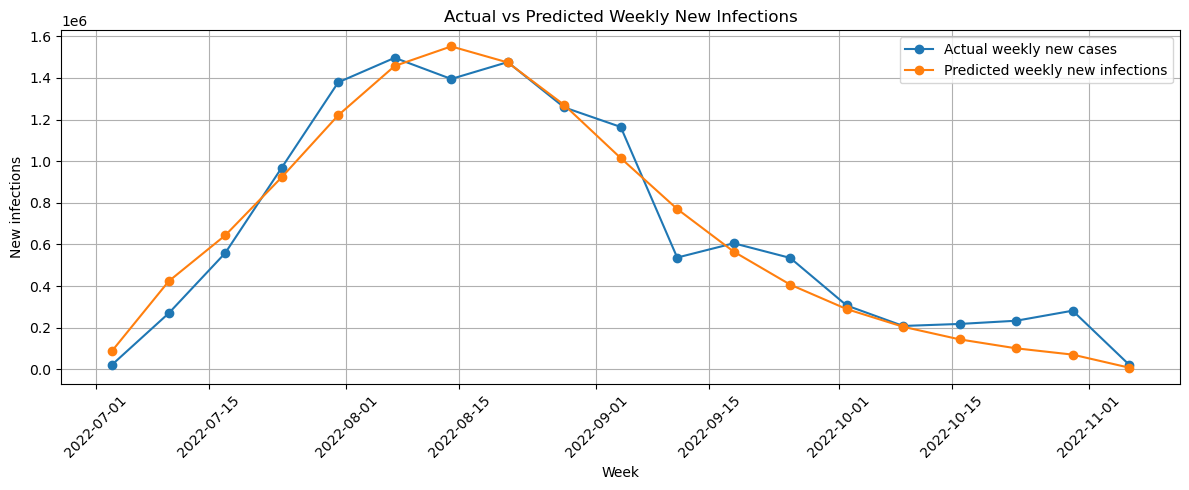

Weekly RMSE: 115079.10423445143
Weekly R2: 0.9494861470019541


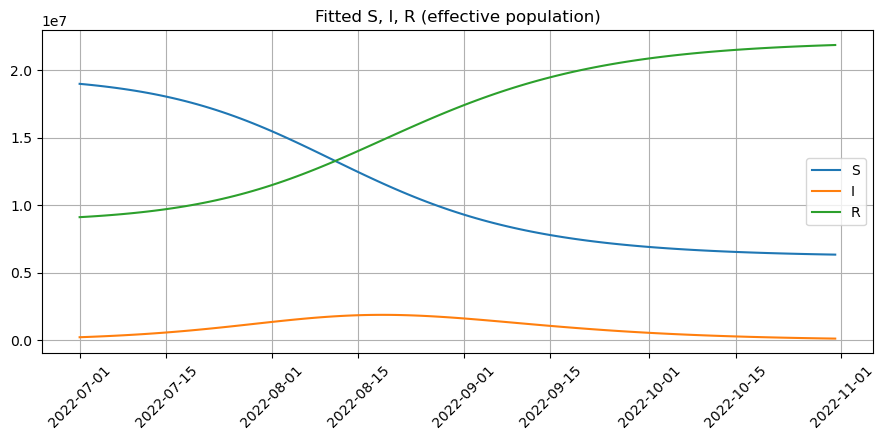

In [14]:

# PREDICTED VS ACTUAL

sol = simulate(beta_best, gamma_best, N_eff)

S_fit, I_fit, R_fit = sol[:, 0], sol[:, 1], sol[:, 2]


daily_pred = S_fit[:-1] - S_fit[1:]

predicted_daily = pd.Series(daily_pred,index=dates.iloc[1:].values)

predicted_weekly = predicted_daily.resample('W-SUN').sum()

comparison = pd.concat([observed_weekly.rename('Actual'),predicted_weekly.rename('Predicted')],
    axis=1).dropna()

plt.figure(figsize=(12, 5))
plt.plot(comparison.index, comparison['Actual'],marker='o', label='Actual weekly new cases')

plt.plot(comparison.index, comparison['Predicted'],marker='o', label='Predicted weekly new infections')

plt.xlabel('Week')
plt.ylabel('New infections')
plt.title('Actual vs Predicted Weekly New Infections')
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))

def r2(actual, predicted):
    return 1 - ( np.sum((actual - predicted) ** 2) /
        np.sum((actual - np.mean(actual)) ** 2))

actual_weekly = comparison['Actual'].values
pred_weekly = comparison['Predicted'].values

print("Weekly RMSE:", rmse(actual_weekly, pred_weekly))
print("Weekly R2:", r2(actual_weekly, pred_weekly))


# FITTED S, I, R CURVES 

plt.figure(figsize=(9, 4.5))
plt.plot(dates, S_fit, label='S'); plt.plot(dates, I_fit, label='I'); plt.plot(dates, R_fit, label='R')
plt.title('Fitted S, I, R (effective population)')
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<a id='section6'></a>
# 6. Comparative Analysis: India vs Japan

We compare the fitted parameters and model performance for both countries.

,Parameter,India,Japan
0,Study Period,Feb 2021 - Aug 2021,Jul 2022 - Oct 2022
1,Beta (Transmission Rate),0.095,0.2663
2,Gamma (Recovery Rate),0.0196,0.1093
3,R0 (Basic Reproduction Number),4.846939,2.436414
4,Effective Population Fraction (%),2.6,22.67
5,Effective Population,37061003,28332786
6,Average Infectious Period (days),51.020408,9.149131
7,Weekly RMSE,347831.3173,115079.1042
8,Weekly R2,0.811283,0.949486


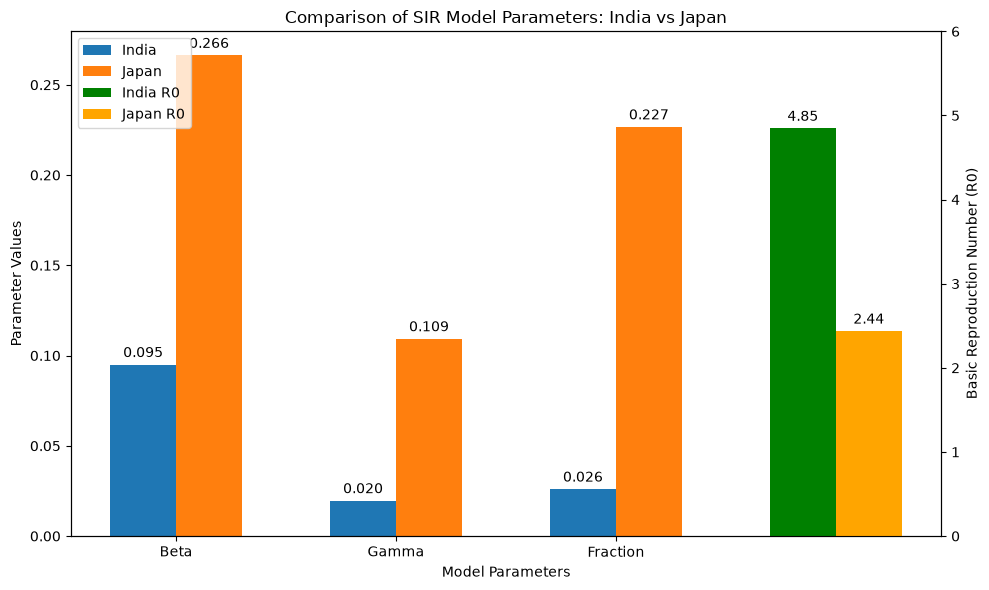

In [14]:
india = {
    'Beta': 0.0950,
    'Gamma': 0.0196,
    'R0': 0.0950 / 0.0196,
    'Fraction': 0.0260,
    'Effective Population': 37061003,
    'Weekly RMSE': 347831.3173,
    'Weekly R2': 0.8112826 }

japan = {
    'Beta': 0.2663,
    'Gamma': 0.1093,
    'R0': 0.2663 / 0.1093,
    'Fraction': 0.2267,
    'Effective Population': 28332786,
    'Weekly RMSE': 115079.1042,
    'Weekly R2': 0.9494861 }
comparison_data = {
    'Parameter': [
        'Study Period',
        'Beta (Transmission Rate)',
        'Gamma (Recovery Rate)',
        'R0 (Basic Reproduction Number)',
        'Effective Population Fraction (%)',
        'Effective Population',
        'Average Infectious Period (days)',
        'Weekly RMSE',
        'Weekly R2'],

    'India': [
        'Feb 2021 - Aug 2021',
        india['Beta'],
        india['Gamma'],
        india['R0'],
        india['Fraction'] * 100,
        india['Effective Population'],
        1 / india['Gamma'],
        india['Weekly RMSE'],
        india['Weekly R2']
    ],

    'Japan': [
        'Jul 2022 - Oct 2022',
        japan['Beta'],
        japan['Gamma'],
        japan['R0'],
        japan['Fraction'] * 100,
        japan['Effective Population'],
        1 / japan['Gamma'],
        japan['Weekly RMSE'],
        japan['Weekly R2']
    ]
}

comparison_df = pd.DataFrame(comparison_data)

display(comparison_df)

parameters = ['Beta', 'Gamma', 'R0', 'Fraction']

india_values = [
    india['Beta'],
    india['Gamma'],
    india['R0'],
    india['Fraction']]

japan_values = [
    japan['Beta'],
    japan['Gamma'],
    japan['R0'],
    japan['Fraction']]

parameters = ['Beta', 'Gamma', 'Fraction']

india_values = [india[p] for p in parameters]
japan_values = [japan[p] for p in parameters]

x = np.arange(len(parameters))
width = 0.30

fig, ax1 = plt.subplots(figsize=(10, 6))
bars1 = ax1.bar(x - width/2, india_values, width,label='India')
bars2 = ax1.bar(x + width/2, japan_values, width,label='Japan')

ax1.set_xlabel('Model Parameters')
ax1.set_ylabel('Parameter Values')
ax1.set_xticks(x)
ax1.set_xticklabels(parameters)
ax1.set_title('Comparison of SIR Model Parameters: India vs Japan')

ax1.bar_label(bars1, fmt='%.3f', padding=3)
ax1.bar_label(bars2, fmt='%.3f', padding=3)

ax2 = ax1.twinx()
r0_x = len(parameters)
r0_width = 0.30
r0_bars1 = ax2.bar(r0_x - r0_width/2, india['R0'], r0_width,
    label='India R0', color='green')

r0_bars2 = ax2.bar(r0_x + r0_width/2, japan['R0'], r0_width,
    label='Japan R0', color='orange')

ax2.set_ylabel('Basic Reproduction Number (R0)')
ax2.set_ylim(0, 6)

ax2.bar_label(r0_bars1, fmt='%.2f', padding=3)
ax2.bar_label(r0_bars2, fmt='%.2f', padding=3)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(handles1 + handles2,labels1 + labels2,loc='upper left')
plt.tight_layout()
plt.show()

<a id='section7'></a>
# 7. Flattening the Curve: Scenario Analysis

We simulate two scenarios for each country:
- **High Transmission**: Best-fit $\beta$ (no intervention)
- **Low Transmission**: Reduced $\beta$ (simulating NPIs: masks, distancing, lockdowns)

The reduction in $\beta$ demonstrates how non-pharmaceutical interventions "flatten the curve" — reducing peak infections and delaying the peak, giving healthcare systems time to respond.

Transmission rate (beta): 0.095 per day
Recovery rate (gamma): 0.0196 per day
Average infectious period: 51.02040816326531 days
Basic reproduction number (R0): 4.846938775510204

Note:Reproduction number is greater than 1 so infection grow initially


Basic reproduction number (R0) : 3.571428571428572


Initial Recovered Population: 10571773
Total Population: 37061003

Scenario: Higher Transmission
Beta: 0.095
Gamma: 0.0196
R0: 4.85
Peak Infected: 9456822.83
Peak Day: 124
Peak found within simulation period.

Scenario: Lower Transmission
Beta: 0.07
Gamma: 0.0196
R0: 3.57
Peak Infected: 6487998.05
Peak Day: 177
Peak found within simulation period.




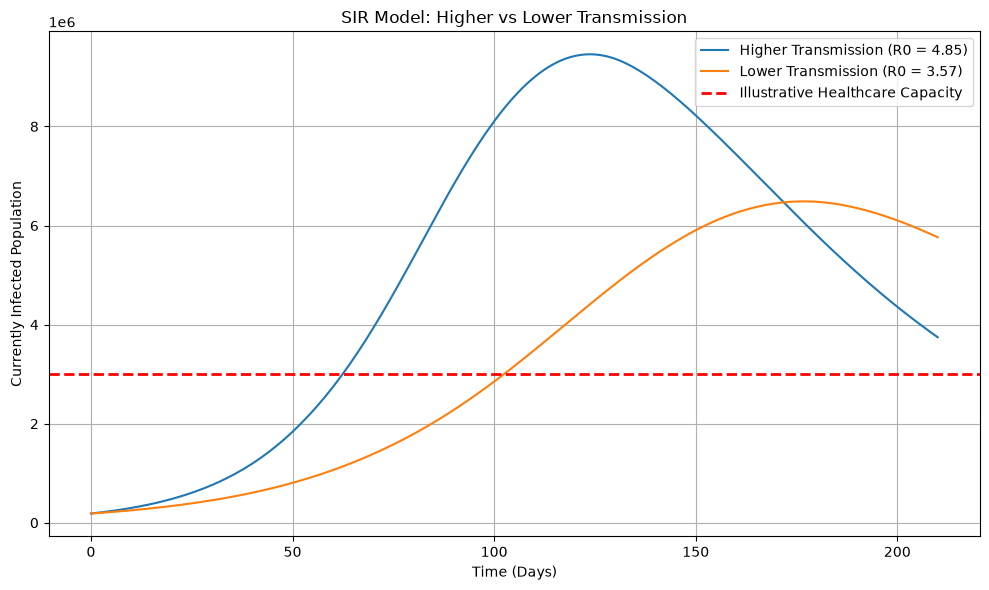

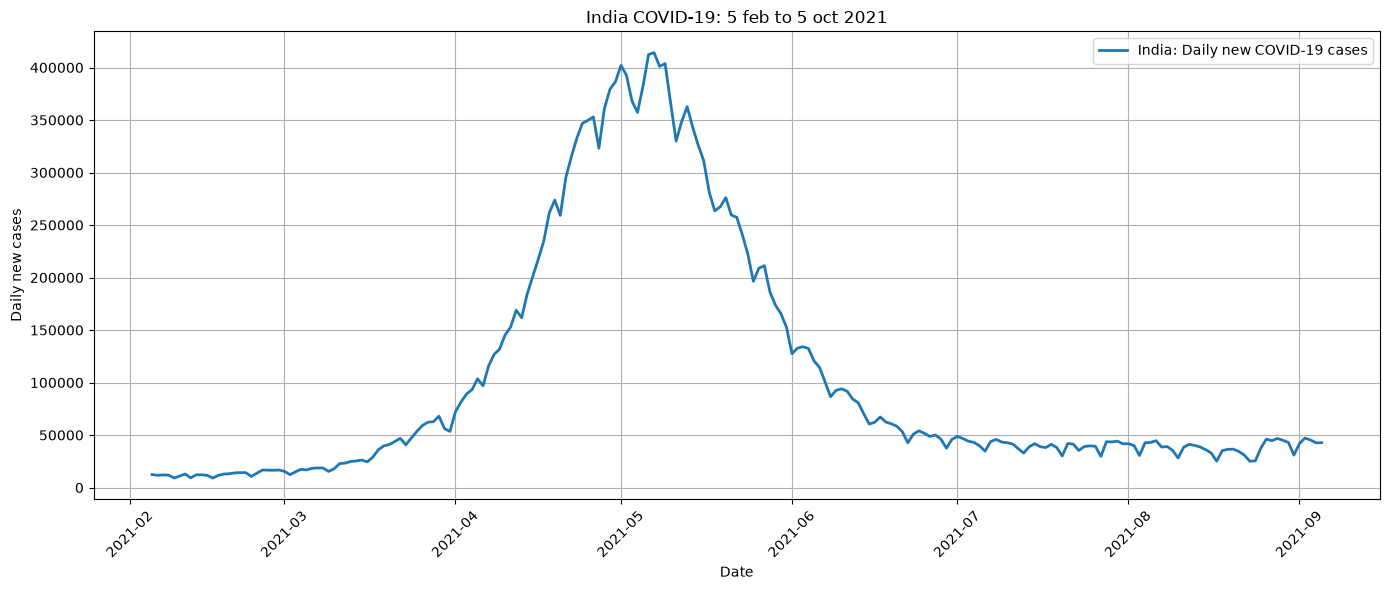

Start date: 2021-02-05 00:00:00
End date: 2021-09-05 00:00:00
Number of dates: 213


Peak date: 2021-05-07
Peak daily new cases: 414188
Number of dates: 213


First date: 2021-02-05 00:00:00
Last date: 2021-09-05 00:00:00
      date  new_cases
2021-02-05    12408.0
2021-02-06    11713.0
2021-02-07    12059.0
2021-02-08    11831.0
2021-02-09     9110.0
2021-02-10    11067.0
2021-02-11    12923.0
2021-02-12     9309.0
2021-02-13    12143.0
2021-02-14    12194.0
2021-02-15    11649.0
2021-02-16     9121.0
2021-02-17    11610.0
2021-02-18    12881.0
2021-02-19    13193.0
2021-02-20    13993.0
2021-02-21    14264.0
2021-02-22    14199.0
2021-02-23    10584.0
2021-02-24    13742.0
2021-02-25    16738.0
2021-02-26    16577.0
2021-02-27    16488.0
2021-02-28    16752.0
2021-03-01    15510.0
2021-03-02    12286.0
2021-03-03    14989.0
2021-03-04    17407.0
2021-03-05    16838.0
2021-03-06    18327.0
2021-03-07    18711.0
2021-03-08    18599.0
2021-03-09    15388.0
2021-03-10    17921.0
2021-03-

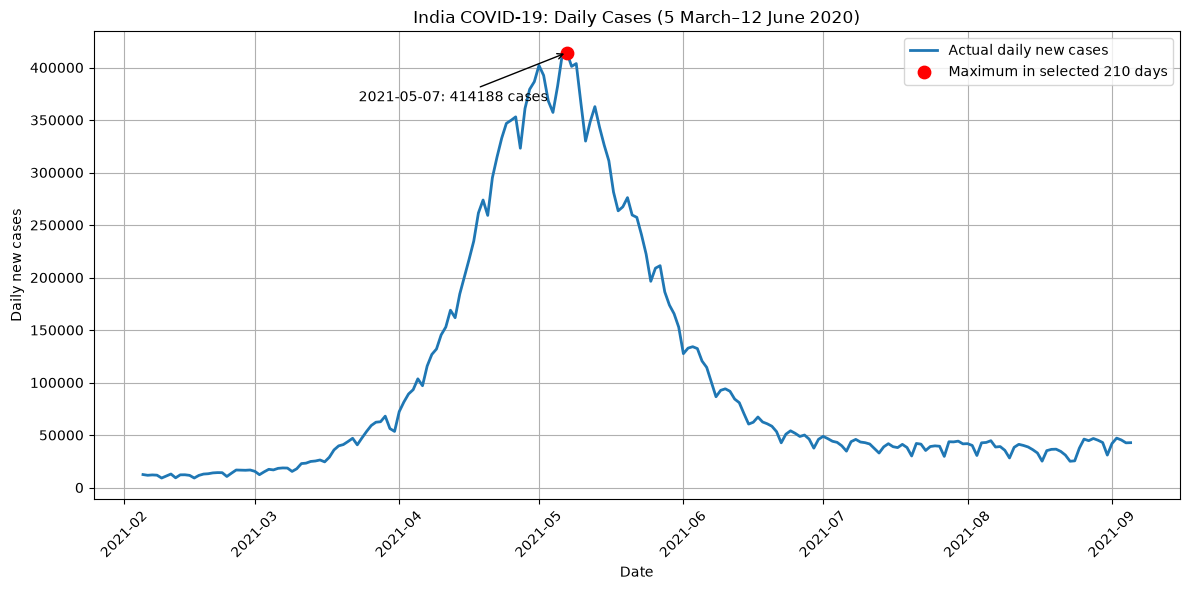



Peak infected: 9456822.83
Day of peak: 124

Peak infected: 6487998.05
Day of peak: 177





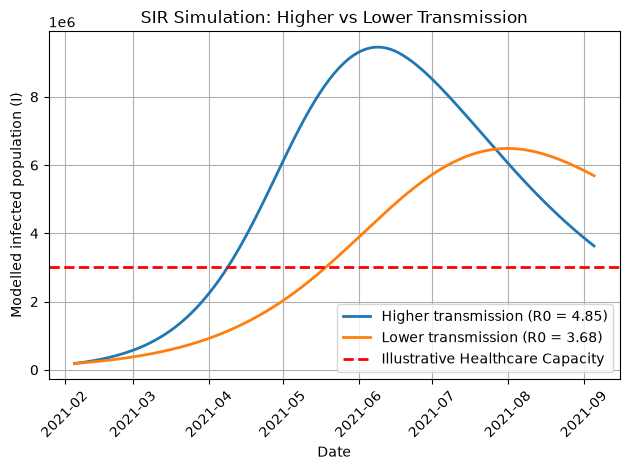

In [15]:
#R0 For India.

# SIR model parameters
beta = 0.095
gamma = 0.0196

# Basic reproduction number
R0 = beta / gamma

print("Transmission rate (beta):", beta, "per day")
print("Recovery rate (gamma):", gamma, "per day")
print("Average infectious period:", 1 / gamma, "days")
print("Basic reproduction number (R0):", R0)

print()
if(R0>1):
    print("Note:Reproduction number is greater than 1 so infection grow initially")
elif(R0==1):
    print("Note:Threshold condition")
elif(R0<1):
    print("Note:Reproduction Number is less than 1 so infection will decline")



print()
print()

#Part Two :Different comaprision (Beta,Gymma)

beta =0.070
gamma = 0.0196

R0 = beta/gamma
print("Basic reproduction number (R0) :",R0)


print()
print()


import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Initial population
N = 37061003
S0 = 26303393
I0 = 185837

# Calculate initial recovered population
R_initial = N - S0 - I0

print("Initial Recovered Population:", R_initial)
print("Total Population:", S0 + I0 + R_initial)

# Time range: 0 to 210 days
t = np.arange(0, 211, 1)

# SIR model
def sir_model(t, y, beta, gamma):
    S, I, R = y

    dS_dt = -beta * S * I / N
    dI_dt = beta * S * I / N - gamma * I
    dR_dt = gamma * I

    return [dS_dt, dI_dt, dR_dt]


# Two transmission scenarios
scenarios = [
    {
        "beta": 0.095,
        "gamma": 0.0196,
        "label": "Higher Transmission"
    },
    {
        "beta": 0.070,
        "gamma": 0.0196,
        "label": "Lower Transmission"
    }
]

plt.figure(figsize=(10, 6))

for scenario in scenarios:

    beta = scenario["beta"]
    gamma = scenario["gamma"]

    # Calculate R0
    reproduction_number = beta / gamma

    solution = solve_ivp(
        sir_model,
        (t[0], t[-1]),
        [S0, I0, R_initial],
        t_eval=t,
        args=(beta, gamma)
    )

    # Check successful simulation
    if not solution.success:
        print("Simulation failed:", solution.message)
        continue

    S, I, R = solution.y

    # Find peak infection
    peak_index = np.argmax(I)

    peak_infected = I[peak_index]
    peak_day = t[peak_index]

    print("\nScenario:", scenario["label"])
    print("Beta:", beta)
    print("Gamma:", gamma)
    print("R0:", round(reproduction_number, 2))
    print("Peak Infected:", round(peak_infected, 2))
    print("Peak Day:", peak_day)

    if peak_index == len(t) - 1:
        print("Peak not confirmed within simulation period.")
    else:
        print("Peak found within simulation period.")

    # Plot infected population
    label = scenario["label"] + " (R0 = " + str(round(reproduction_number, 2)) + ")"

    plt.plot(t, I, label=label)



print()
print()


# Illustrative healthcare capacity
hospital_capacity = 3000000

plt.axhline(
    y=hospital_capacity,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Illustrative Healthcare Capacity"
)


plt.xlabel("Time (Days)")
plt.ylabel("Currently Infected Population")
plt.title("SIR Model: Higher vs Lower Transmission")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



print()
print()

#Part 3: Flattening the curve

#Note: graph representation of second wave
# Convert date column to datetime
india =pd.read_csv(r"Data/india_covid_cleaned.csv")
india["date"] = pd.to_datetime(
    india["date"], errors="coerce"
)

# Select 210 days starting from 5 feb 2021
start_date = pd.Timestamp("2021-02-05")
end_date = pd.Timestamp("2021-09-05")

india_100 = india[
    (india["date"] >= start_date) &
    (india["date"] <= end_date)
].copy()

india_100 = india_100.sort_values("date")
india_100 = india_100.drop_duplicates(subset="date")

# Ensure new_cases is numeric
india_100["new_cases"] = pd.to_numeric(
    india_100["new_cases"], errors="coerce"
)

# Plot the real-world data
plt.figure(figsize=(14, 6))

plt.plot(
    india_100["date"],
    india_100["new_cases"],
    label="India: Daily new COVID-19 cases",
    linewidth=2
)

plt.xlabel("Date")
plt.ylabel("Daily new cases")
plt.title("India COVID-19: 5 feb to 5 oct 2021")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Start date:", india_100["date"].min())
print("End date:", india_100["date"].max())
print("Number of dates:", india_100["date"].nunique())



print()
print()


# Use ONLY the selected 210-day dataset
valid_data = india_100.dropna(subset=["new_cases"]).copy()

peak_index = valid_data["new_cases"].idxmax()
peak_row = valid_data.loc[peak_index]

print("Peak date:", peak_row["date"].strftime("%Y-%m-%d"))
print("Peak daily new cases:", int(peak_row["new_cases"]))
print("Number of dates:", valid_data["date"].nunique())


print()
print()


print("First date:", india_100["date"].min())
print("Last date:", india_100["date"].max())

print(
    india_100[["date", "new_cases"]]
    .head(100)
    .to_string(index=False)
)


print()
print()


# Find maximum daily cases in the selected 210 days
valid_data = india_100.dropna(subset=["new_cases"]).copy()

peak_index = valid_data["new_cases"].idxmax()
peak_row = valid_data.loc[peak_index]

peak_date = peak_row["date"]
peak_cases = peak_row["new_cases"]

plt.figure(figsize=(12, 6))

plt.plot(
    valid_data["date"],
    valid_data["new_cases"],
    label="Actual daily new cases",
    linewidth=2
)

plt.scatter(
    peak_date,
    peak_cases,
    color="red",
    s=80,
    label="Maximum in selected 210 days",
    zorder=3
)

plt.annotate(
    f"{peak_date:%Y-%m-%d}: {int(peak_cases)} cases",
    (peak_date, peak_cases),
    xytext=(-150, -35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

plt.xlabel("Date")
plt.ylabel("Daily new cases")
plt.title("India COVID-19: Daily Cases (5 March–12 June 2020)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


print()
print()


# part 3 flattening the curve & Hospital capacity

from scipy.integrate import solve_ivp
N=37061003
S0=26303393
I0=185837
R_initial=10571773
# Use the 210-day window for the calendar dates
dates = india_100["date"].drop_duplicates().sort_values().reset_index(drop=True)

# Use 100 daily time points for the simulation
t_sim = np.arange(len(dates))

scenarios = [
    {"beta": 0.095, "gamma": 0.0196,
     "label": "Higher transmission (R0 = 4.85)"},
    {"beta": 0.070, "gamma": 0.0196,
     "label": "Lower transmission (R0 = 3.68)"}
]

def sir_model(t, y, beta, gamma):
    S, I, R = y

    dS_dt = -beta * S * I / N
    dI_dt = beta * S * I / N - gamma * I
    dR_dt = gamma * I

    return [dS_dt, dI_dt, dR_dt]

for scenario in scenarios:
    beta = scenario["beta"]
    gamma = scenario["gamma"]

    solution = solve_ivp(
        sir_model,
        (0, len(dates) - 1),
        [S0, I0, R_initial],
        t_eval=t_sim,
        args=(beta, gamma)
    )

    I = solution.y[1]

    peak_index = np.argmax(I)

    peak_infected = I[peak_index]
    peak_day = t_sim[peak_index]

    print("Peak infected:", round(peak_infected, 2))
    print("Day of peak:", round(peak_day, 2))
    print("")

    

    plt.plot(
        dates,
        I,
        label=scenario["label"],
        linewidth=2
    )


print()
print()

# Illustrative healthcare capacity
hospital_capacity = 3000000

plt.axhline(
    y=hospital_capacity,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Illustrative Healthcare Capacity"
)
plt.xlabel("Date")
plt.ylabel("Modelled infected population (I)")
plt.title("SIR Simulation: Higher vs Lower Transmission")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




Transmission rate (beta): 0.2663 per day
Recovery rate (gamma): 0.1093 per day
Average infectious period: 9.149130832570906 days
Basic reproduction number (R0): 2.436413540713632

Note:Reproduction number is greater than 1 so infection grow initially


Basic reproduction number (R0) : 1.7849954254345837


Initial Recovered Population: 9117228
Total Population: 28332786

Scenario: Higher Transmission
Beta: 0.2663
Gamma: 0.1093
R0: 2.44
Peak Infected: 1890493.58
Peak Day: 49
Peak found within simulation period.

Scenario: Lower Transmission
Beta: 0.1951
Gamma: 0.1093
R0: 1.78
Peak Infected: 505059.44
Peak Day: 65
Peak found within simulation period.


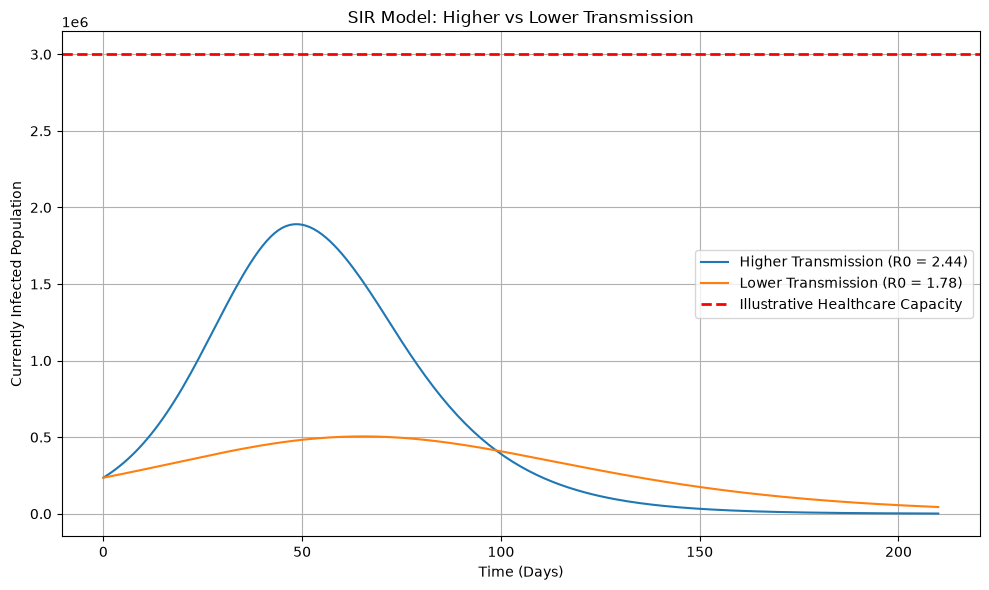

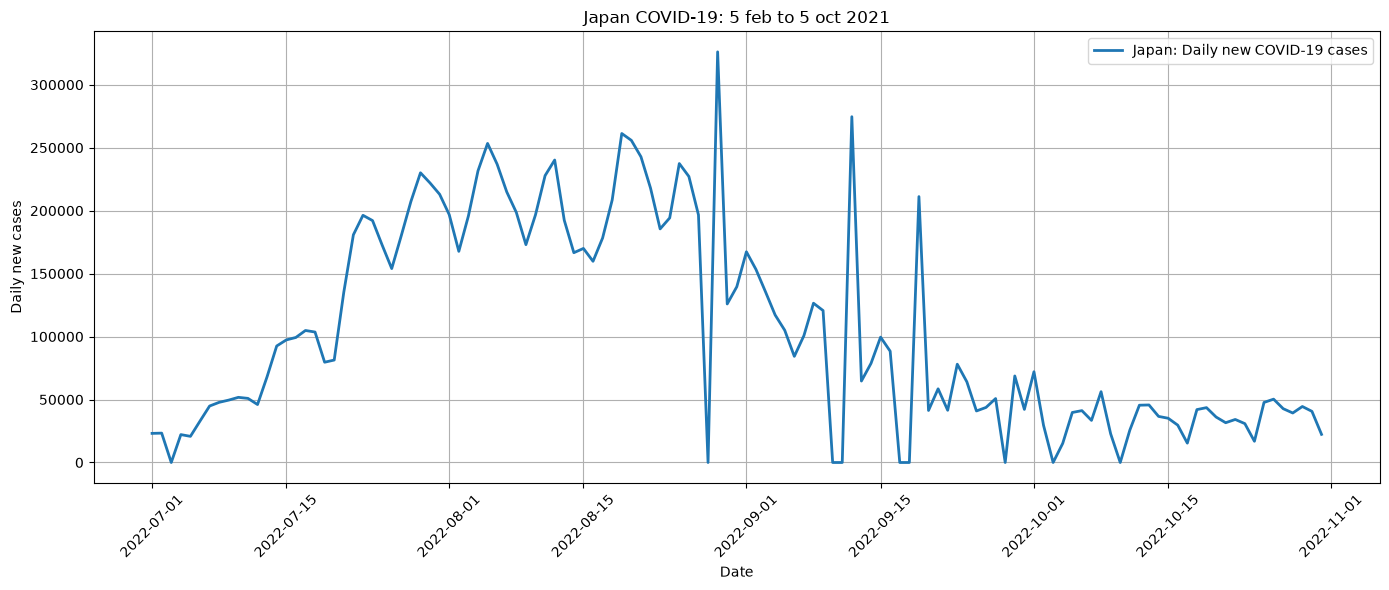

Start date: 2022-07-01 00:00:00
End date: 2022-10-31 00:00:00
Number of dates: 123


Peak date: 2022-08-29
Peak daily new cases: 326090
Number of dates: 123


First date: 2022-07-01 00:00:00
Last date: 2022-10-31 00:00:00
      date  new_cases
2022-07-01    23125.0
2022-07-02    23327.0
2022-07-03        0.0
2022-07-04    22154.0
2022-07-05    20774.0
2022-07-06    32906.0
2022-07-07    44845.0
2022-07-08    47786.0
2022-07-09    49557.0
2022-07-10    51738.0
2022-07-11    50918.0
2022-07-12    46033.0
2022-07-13    68191.0
2022-07-14    92507.0
2022-07-15    97339.0
2022-07-16    99291.0
2022-07-17   104832.0
2022-07-18   103602.0
2022-07-19    79633.0
2022-07-20    81362.0
2022-07-21   135239.0
2022-07-22   180826.0
2022-07-23   196297.0
2022-07-24   192109.0
2022-07-25   172673.0
2022-07-26   154011.0
2022-07-27   180226.0
2022-07-28   207236.0
2022-07-29   230055.0
2022-07-30   221938.0
2022-07-31   212960.0
2022-08-01   196812.0
2022-08-02   167678.0
2022-08-03   195801.0
2022-08-

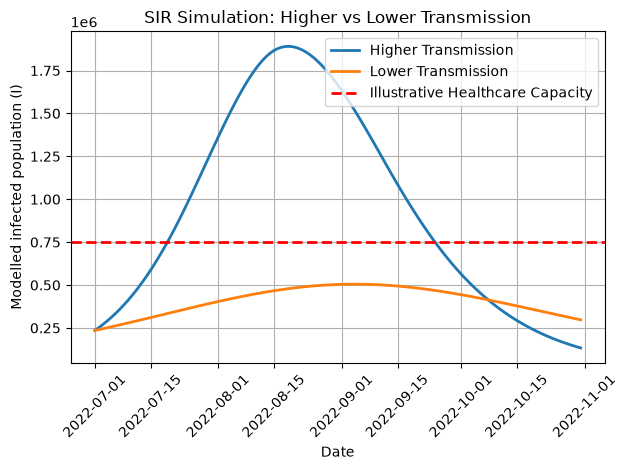

In [16]:
#Part Two :R0 calulation

#R0 For Japan.

# SIR model parameters
beta = 0.2663
gamma = 0.1093

# Basic reproduction number
R0 = beta / gamma

print("Transmission rate (beta):", beta, "per day")
print("Recovery rate (gamma):", gamma, "per day")
print("Average infectious period:", 1 / gamma, "days")
print("Basic reproduction number (R0):", R0)

print()
if(R0>1):
    print("Note:Reproduction number is greater than 1 so infection grow initially")
elif(R0==1):
    print("Note:Threshold condition")
elif(R0<1):
    print("Note:Reproduction Number is less than 1 so infection will decline")


print()
print()


#Part Two :Different comaprision (Beta,Gymma)

beta =0.1951
gamma = 0.1093

R0 = beta/gamma
print("Basic reproduction number (R0) :",R0)



print()
print()

# Initial population
N = 28332786
S0 = 18980141
I0 = 235417

# Calculate initial recovered population
R_initial = N - S0 - I0

print("Initial Recovered Population:", R_initial)
print("Total Population:", S0 + I0 + R_initial)

# Time range: 0 to 210 days
t = np.arange(0, 211, 1)

# SIR model
def sir_model(t, y, beta, gamma):
    S, I, R = y

    dS_dt = -beta * S * I / N
    dI_dt = beta * S * I / N - gamma * I
    dR_dt = gamma * I

    return [dS_dt, dI_dt, dR_dt]


# Two transmission scenarios
scenarios = [
    {
        "beta": 0.2663,
        "gamma": 0.1093,
        "label": "Higher Transmission"
    },
    {
        "beta": 0.1951,
        "gamma": 0.1093,
        "label": "Lower Transmission"
    }
]

plt.figure(figsize=(10, 6))

for scenario in scenarios:

    beta = scenario["beta"]
    gamma = scenario["gamma"]

    # Calculate R0
    reproduction_number = beta / gamma

    solution = solve_ivp(
        sir_model,
        (t[0], t[-1]),
        [S0, I0, R_initial],
        t_eval=t,
        args=(beta, gamma)
    )

    # Check successful simulation
    if not solution.success:
        print("Simulation failed:", solution.message)
        continue

    S, I, R = solution.y

    # Find peak infection
    peak_index = np.argmax(I)

    peak_infected = I[peak_index]
    peak_day = t[peak_index]

    print("\nScenario:", scenario["label"])
    print("Beta:", beta)
    print("Gamma:", gamma)
    print("R0:", round(reproduction_number, 2))
    print("Peak Infected:", round(peak_infected, 2))
    print("Peak Day:", peak_day)

    if peak_index == len(t) - 1:
        print("Peak not confirmed within simulation period.")
    else:
        print("Peak found within simulation period.")

    # Plot infected population
    label = scenario["label"] + " (R0 = " + str(round(reproduction_number, 2)) + ")"

    plt.plot(t, I, label=label)




# Illustrative healthcare capacity
hospital_capacity = 3000000

plt.axhline(
    y=hospital_capacity,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Illustrative Healthcare Capacity"
)


plt.xlabel("Time (Days)")
plt.ylabel("Currently Infected Population")
plt.title("SIR Model: Higher vs Lower Transmission")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


print()
print()


#Part 3: Flattening the curve

#Note: graph representation of second wave
# Convert date column to datetime
japan =pd.read_csv(r"Data/japan_covid_cleaned.csv")
japan["date"] = pd.to_datetime(
    japan["date"], errors="coerce"
)

# Select 100 days starting from july 2022
start_date = pd.Timestamp("2022-07-01")
end_date = pd.Timestamp("2022-10-31")

japan_100 = japan[
    (japan["date"] >= start_date) &
    (japan["date"] <= end_date)
].copy()

japan_100 = japan_100.sort_values("date")
japan_100 = japan_100.drop_duplicates(subset="date")

# Ensure new_cases is numeric
japan_100["new_cases"] = pd.to_numeric(
    japan_100["new_cases"], errors="coerce"
)

# Plot the real-world data
plt.figure(figsize=(14, 6))

plt.plot(
    japan_100["date"],
    japan_100["new_cases"],
    label="Japan: Daily new COVID-19 cases",
    linewidth=2
)

plt.xlabel("Date")
plt.ylabel("Daily new cases")
plt.title("Japan COVID-19: 5 feb to 5 oct 2021")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Start date:", japan_100["date"].min())
print("End date:", japan_100["date"].max())
print("Number of dates:", japan_100["date"].nunique())



print()
print()

# Use ONLY the selected 100-day dataset
valid_data = japan_100.dropna(subset=["new_cases"]).copy()

peak_index = valid_data["new_cases"].idxmax()
peak_row = valid_data.loc[peak_index]

print("Peak date:", peak_row["date"].strftime("%Y-%m-%d"))
print("Peak daily new cases:", int(peak_row["new_cases"]))
print("Number of dates:", valid_data["date"].nunique())


print()
print()

print("First date:", japan_100["date"].min())
print("Last date:", japan_100["date"].max())

print(
    japan_100[["date", "new_cases"]]
    .head(100)
    .to_string(index=False)
)


print()
print()


# part 3 flattening the curve & Hospital capacity

from scipy.integrate import solve_ivp

N = 28332786
S0 = 18980141
I0 = 235417
R_initial=N-S0-I0
# Use the 210-day window for the calendar dates
dates = japan_100["date"].drop_duplicates().sort_values().reset_index(drop=True)

# Use 100 daily time points for the simulation
t_sim = np.arange(len(dates))

scenarios = [
    {
        "beta": 0.2663,
        "gamma": 0.1093,
        "label": "Higher Transmission"
    },
    {
        "beta": 0.1951,
        "gamma": 0.1093,
        "label": "Lower Transmission"
    }
]

def sir_model(t, y, beta, gamma):
    S, I, R = y

    dS_dt = -beta * S * I / N
    dI_dt = beta * S * I / N - gamma * I
    dR_dt = gamma * I

    return [dS_dt, dI_dt, dR_dt]

for scenario in scenarios:
    beta = scenario["beta"]
    gamma = scenario["gamma"]

    solution = solve_ivp(
        sir_model,
        (0, len(dates) - 1),
        [S0, I0, R_initial],
        t_eval=t_sim,
        args=(beta, gamma)
    )

    I = solution.y[1]

    peak_index = np.argmax(I)

    peak_infected = I[peak_index]
    peak_day = t_sim[peak_index]

    print("Peak infected:", round(peak_infected, 2))
    print("Day of peak:", round(peak_day, 2))
    print("")

    

    plt.plot(
        dates,
        I,
        label=scenario["label"],
        linewidth=2
    )


# Illustrative healthcare capacity
hospital_capacity = 750000

plt.axhline(
    y=hospital_capacity,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Illustrative Healthcare Capacity"
)
plt.xlabel("Date")
plt.ylabel("Modelled infected population (I)")
plt.title("SIR Simulation: Higher vs Lower Transmission")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




<a id='section8'></a>
# 8. Bonus: Bombay Plague 1905–06

## 8.1 Historical Context

The 1905–06 Bombay plague epidemic was one of the most severe plague outbreaks in colonial India. Weekly mortality data was published by the Bombay Plague Committee.

## 8.2 Data Source

- File: `bombay_plague_data.xlsx`
- Contains weekly plague cases and deaths for Bombay City and surrounding districts
- Period: September 1896 – June 1899 (we focus on the 1905–06 wave)

## 8.3 Methodology

1. Extract Bombay City weekly deaths for 1905–06
2. Assume infectious period $D = 14$ days (consistent with plague pneumonic form)
3. Estimate $I(t)$ and $R(t)$ from weekly deaths
4. Fit SIR parameters using same grid search approach
5. Compare with historical records

<>:96: SyntaxWarning: invalid escape sequence '\o'
<>:96: SyntaxWarning: invalid escape sequence '\o'
C:\Users\sangh\AppData\Local\Temp\ipykernel_15796\1813870146.py:96: SyntaxWarning: invalid escape sequence '\o'
  axes[0].plot(t, sech2_func(t, 890, 0.2, 3.4), color='red', linestyle='--', linewidth=2, label='Paper Analytical Fit ($890 \operatorname{sech}^2$)')


           TASK 4: EPIDEMIOLOGICAL MODEL & CURVE FITTING SUMMARY           
Parameter / Metric        | Paper Official     | Custom Fitted     
---------------------------------------------------------------------------
Amplitude (A)             | 890.00             | 585.60            
Growth Rate (w / beta)    | 0.2000             | 0.1145            
Phase Shift (phi)         | 3.4000             | 2.4458            


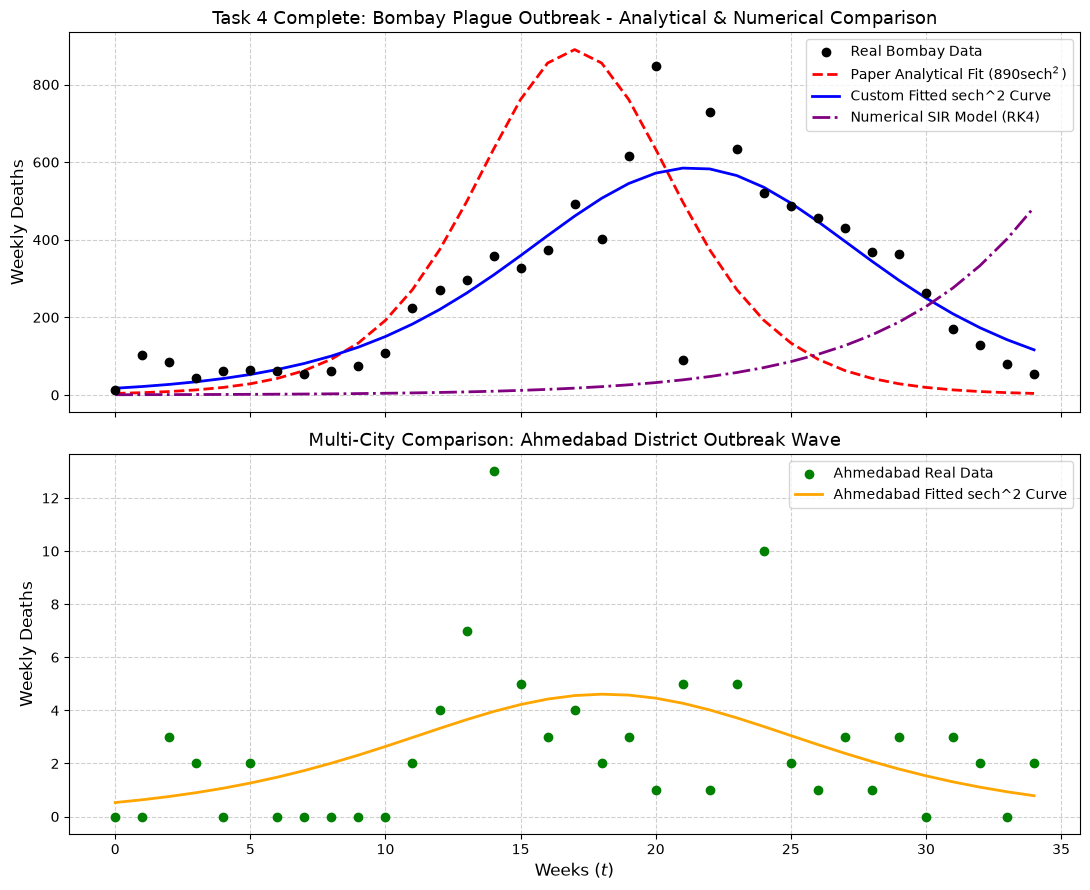

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
try:
    excel_path = "Data/bombay_plague_data_1905.xlsx"
    xls = pd.ExcelFile(excel_path)
    df = pd.read_excel(excel_path, sheet_name=xls.sheet_names[0])
except Exception as e:
    print(f"Error loading file: {e}")

df['week_ending'] = pd.to_datetime(df['week_ending'], errors='coerce')
df['Bombay_deaths'] = pd.to_numeric(df['Bombay_city_plague_deaths'], errors='coerce')
df['Ahmedabad_deaths'] = pd.to_numeric(df['ahmadabad_district_deaths'], errors='coerce')

df_clean = df.dropna(subset=['week_ending']).sort_values('week_ending').reset_index(drop=True)
wave_data = df_clean.head(35).copy()
t = np.arange(len(wave_data))

bombay_deaths = wave_data['Bombay_deaths'].values
ahmadabad_deaths = wave_data['Ahmedabad_deaths'].fillna(0).values

def sech2_func(t, A, w, phi):
    return A * (1 / np.cosh(w * t - phi))**2

try:
    popt_bombay, _ = curve_fit(sech2_func, t, bombay_deaths, p0=[890, 0.2, 3.4], maxfev=10000)
except Exception:
    popt_bombay = [890, 0.2, 3.4] # fallback

try:
    popt_ahm, _ = curve_fit(sech2_func, t, ahmadabad_deaths, p0=[50, 0.15, 2.0], maxfev=10000)
except Exception:
    popt_ahm = [50, 0.15, 2.0]

fit_bombay_custom = sech2_func(t, *popt_bombay)


def rk4_sir_model(N, beta, gamma, I0, weeks_count):
    S0 = N - I0
    R0 = 0.0
    dt = 0.1
    steps_per_week = int(1 / dt)
    total_steps = weeks_count * steps_per_week

    time_series = []
    deaths_series = []

    S, I, R = S0, I0, R0
    weekly_deaths = 0.0

    for step in range(total_steps):

        def derivatives(s, i, r):
            ds = -beta * s * i / N
            di = (beta * s * i / N) - gamma * i
            dr = gamma * i
            return ds, di, dr


        s1, i1, r1 = derivatives(S, I, R)
        s2, i2, r2 = derivatives(S + 0.5*dt*s1, I + 0.5*dt*i1, R + 0.5*dt*r1)
        s3, i3, r3 = derivatives(S + 0.5*dt*s2, I + 0.5*dt*i2, R + 0.5*dt*r2)
        s4, i4, r4 = derivatives(S + dt*s3, I + dt*i3, R + dt*r3)

        S += (dt / 6.0) * (s1 + 2*s2 + 2*s3 + s4)
        I += (dt / 6.0) * (i1 + 2*i2 + 2*i3 + i4)
        R += (dt / 6.0) * (r1 + 2*r2 + 2*r3 + r4)


        weekly_deaths += (gamma * I) * dt * 0.15

        if (step + 1) % steps_per_week == 0:
            deaths_series.append(weekly_deaths)
            weekly_deaths = 0.0

    return np.array(deaths_series[:weeks_count])


fit_rk4 = rk4_sir_model(N=800000, beta=0.45, gamma=0.25, I0=14, weeks_count=len(t))


print("="*75)
print(f"{'TASK 4: EPIDEMIOLOGICAL MODEL & CURVE FITTING SUMMARY':^75}")
print("="*75)
print(f"{'Parameter / Metric':<25} | {'Paper Official':<18} | {'Custom Fitted':<18}")
print("-"*75)
print(f"{'Amplitude (A)':<25} | {890.00:<18.2f} | {popt_bombay[0]:<18.2f}")
print(f"{'Growth Rate (w / beta)':<25} | {0.2000:<18.4f} | {popt_bombay[1]:<18.4f}")
print(f"{'Phase Shift (phi)':<25} | {3.4000:<18.4f} | {popt_bombay[2]:<18.4f}")
print("="*75)

fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

axes[0].scatter(t, bombay_deaths, color='black', label='Real Bombay Data', zorder=5)
axes[0].plot(t, sech2_func(t, 890, 0.2, 3.4), color='red', linestyle='--', linewidth=2, label='Paper Analytical Fit ($890 \operatorname{sech}^2$)')
axes[0].plot(t, fit_bombay_custom, color='blue', linewidth=2, label='Custom Fitted sech^2 Curve')
axes[0].plot(t, fit_rk4, color='purple', linestyle='-.', linewidth=2, label='Numerical SIR Model (RK4)')
axes[0].set_ylabel('Weekly Deaths', fontsize=12)
axes[0].set_title('Task 4 Complete: Bombay Plague Outbreak - Analytical & Numerical Comparison', fontsize=13)
axes[0].legend(fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)


axes[1].scatter(t, ahmadabad_deaths, color='green', label='Ahmedabad Real Data', zorder=5)
axes[1].plot(t, sech2_func(t, *popt_ahm), color='orange', linewidth=2, label='Ahmedabad Fitted sech^2 Curve')
axes[1].set_xlabel('Weeks ($t$)', fontsize=12)
axes[1].set_ylabel('Weekly Deaths', fontsize=12)
axes[1].set_title('Multi-City Comparison: Ahmedabad District Outbreak Wave', fontsize=13)
axes[1].legend(fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
pip install pandas numpy matplotlib

In [18]:
pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


First Wave Data shape: (40, 56)


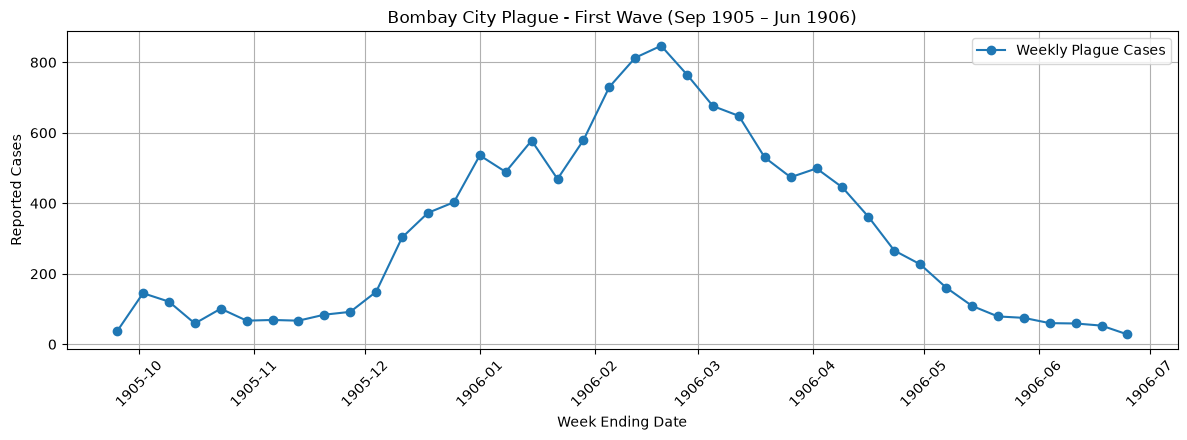

Total Weeks in First Wave: 40
I0 (Initial Infected) = 37.0
R0_init = 0
Coarse best: beta=2.329, gamma=2.171, frac=0.100, error=0.6637 (4s)
Fine best:   beta=2.3286, gamma=2.1714, frac=0.1071, error=0.6117 (4s)

--- Best-Fit Parameters (First Wave) ---
Beta (Transmission rate / week): 2.3286
Gamma (Recovery rate / week): 2.1714
Average infectious period: 0.46 weeks
Effective Population: 107,143 (10.71% of total)

Weekly RMSE: 106.08
Weekly R²: 0.8234


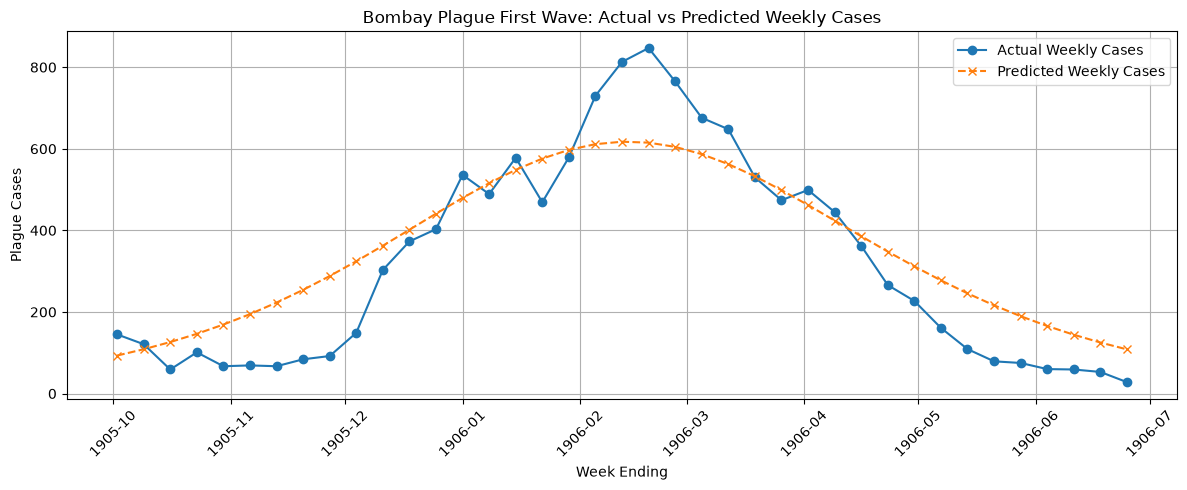

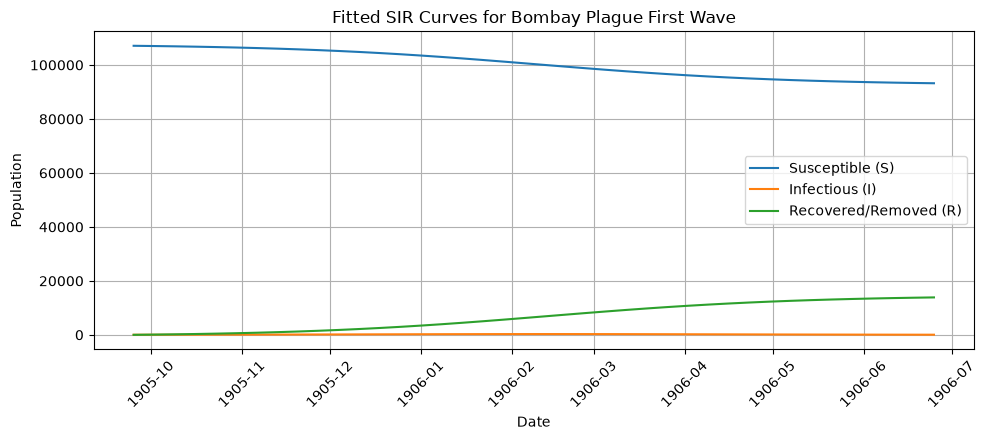

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

# --- यहाँ POP (Total Population) डिफाइन करें ---
POP = 1_000_000  # आप इसे अपनी आवश्यकतानुसार बदल सकते हैं

excel_path = "Data/bombay_plague_data_1905.xlsx"  
xls = pd.ExcelFile(excel_path)
df = pd.read_excel(excel_path, sheet_name=xls.sheet_names[0])

df_clean = df.iloc[:-2].copy()

df_clean['week_ending'] = pd.to_datetime(df_clean['week_ending'])
df_clean['Bombay_city_plague_cases'] = pd.to_numeric(
    df_clean['Bombay_city_plague_cases'], errors='coerce'
)
df_clean = df_clean.dropna(subset=['week_ending', 'Bombay_city_plague_cases'])
df_clean = df_clean.sort_values('week_ending').reset_index(drop=True)

df_clean = df_clean[
    (df_clean['week_ending'] >= '1905-09-25') & 
    (df_clean['week_ending'] <= '1906-06-30')
].copy().reset_index(drop=True)

print(f"First Wave Data shape: {df_clean.shape}")

plt.figure(figsize=(12, 4.5))
plt.plot(df_clean['week_ending'], df_clean['Bombay_city_plague_cases'], marker='o', label='Weekly Plague Cases')
plt.xlabel('Week Ending Date')
plt.ylabel('Reported Cases')
plt.title('Bombay City Plague - First Wave (Sep 1905 – Jun 1906)')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

dates = df_clean['week_ending']
observed_weekly = df_clean['Bombay_city_plague_cases']

n_weeks = len(df_clean)

I0 = observed_weekly.iloc[0]
R0_init = 0

print(f"Total Weeks in First Wave: {n_weeks}")
print(f"I0 (Initial Infected) = {I0}")
print(f"R0_init = {R0_init}")

def sir_rhs_weekly(y, beta, gamma, N):
    S, I, R = y
    new_inf = beta * S * I / N
    return np.array([-new_inf, new_inf - gamma * I, gamma * I])

def rk4_method_weekly(f, y0, t):
    h = t[1] - t[0]
    n = len(t)
    y = np.zeros((n, len(y0)))
    y[0] = y0
    for i in range(n - 1):
        k1 = f(t[i], y[i])
        k2 = f(t[i] + h/2, y[i] + h*k1/2)
        k3 = f(t[i] + h/2, y[i] + h*k2/2)
        k4 = f(t[i] + h,   y[i] + h*k3)
        y[i + 1] = y[i] + (h/6) * (k1 + 2*k2 + 2*k3 + k4)
    return y

t = np.arange(n_weeks, dtype=float)

def simulate(beta, gamma, N_eff):
    y0 = np.array([N_eff - I0 - R0_init, I0, R0_init])
    f = lambda tt, y: sir_rhs_weekly(y, beta, gamma, N_eff)
    return rk4_method_weekly(f, y0, t)

def grid_error(beta, gamma, frac):
    N_eff = frac * POP
    if N_eff <= I0 + R0_init:
        return np.inf

    sol = simulate(beta, gamma, N_eff)
    
    daily_pred = sol[:-1, 0] - sol[1:, 0]
    
    pred_series = pd.Series(daily_pred, index=dates.iloc[1:].values)
    obs_series = pd.Series(observed_weekly.iloc[1:].values, index=dates.iloc[1:].values)

    comparison = pd.concat([obs_series, pred_series], axis=1).dropna()
    if len(comparison) == 0:
        return np.inf

    max_val = max(obs_series.max(), 1)
    return np.sum(((comparison.iloc[:, 1] - comparison.iloc[:, 0]) / max_val) ** 2)

def grid_search(betas, gammas, fracs):
    best_params = None
    best_err = np.inf
    for b in betas:
        for g in gammas:
            for fr in fracs:
                e = grid_error(b, g, fr)
                if e < best_err:
                    best_err = e
                    best_params = (b, g, fr)
    return best_params, best_err

t0 = time.time()
betas1  = np.linspace(0.1, 4.0, 15)
gammas1 = np.linspace(0.1, 3.0, 15)
fracs1  = np.array([0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0])

res1, e1 = grid_search(betas1, gammas1, fracs1)
if res1 is None:
    raise ValueError("Coarse grid search failed. Check ranges.")
b1, g1, f1 = res1
print(f"Coarse best: beta={b1:.3f}, gamma={g1:.3f}, frac={f1:.3f}, error={e1:.4f} ({time.time()-t0:.0f}s)")

t0 = time.time()
betas2  = np.linspace(max(b1 - 0.4, 0.01), b1 + 0.4, 15)
gammas2 = np.linspace(max(g1 - 0.4, 0.01), g1 + 0.4, 15)
fracs2  = np.linspace(max(f1 * 0.5, 0.02), min(f1 * 1.5, 1.0), 8)

res2, e2 = grid_search(betas2, gammas2, fracs2)
if res2 is None:
    beta_best, gamma_best, frac_best = b1, g1, f1
else:
    beta_best, gamma_best, frac_best = res2

N_eff = frac_best * POP
print(f"Fine best:   beta={beta_best:.4f}, gamma={gamma_best:.4f}, frac={frac_best:.4f}, error={e2:.4f} ({time.time()-t0:.0f}s)")

S0 = N_eff - I0 - R0_init

print("\n--- Best-Fit Parameters (First Wave) ---")
print(f"Beta (Transmission rate / week): {beta_best:.4f}")
print(f"Gamma (Recovery rate / week): {gamma_best:.4f}")
print(f"Average infectious period: {1 / gamma_best:.2f} weeks")
print(f"Effective Population: {N_eff:,.0f} ({frac_best*100:.2f}% of total)")

sol = simulate(beta_best, gamma_best, N_eff)
S_fit, I_fit, R_fit = sol[:, 0], sol[:, 1], sol[:, 2]

predicted_weekly_vals = S_fit[:-1] - S_fit[1:]
comparison = pd.DataFrame({
    'Actual': observed_weekly.iloc[1:].values,
    'Predicted': predicted_weekly_vals
}, index=dates.iloc[1:].values).dropna()

def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))

def r2(actual, predicted):
    return 1 - (np.sum((actual - predicted) ** 2) / np.sum((actual - np.mean(actual)) ** 2))

print(f"\nWeekly RMSE: {rmse(comparison['Actual'], comparison['Predicted']):.2f}")
print(f"Weekly R²: {r2(comparison['Actual'], comparison['Predicted']):.4f}")

plt.figure(figsize=(12, 5))
plt.plot(comparison.index, comparison['Actual'], marker='o', label='Actual Weekly Cases')
plt.plot(comparison.index, comparison['Predicted'], marker='x', linestyle='--', label='Predicted Weekly Cases')
plt.xlabel('Week Ending')
plt.ylabel('Plague Cases')
plt.title('Bombay Plague First Wave: Actual vs Predicted Weekly Cases')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4.5))
plt.plot(dates, S_fit, label='Susceptible (S)')
plt.plot(dates, I_fit, label='Infectious (I)')
plt.plot(dates, R_fit, label='Recovered/Removed (R)')
plt.title('Fitted SIR Curves for Bombay Plague First Wave')
plt.xlabel('Date')
plt.ylabel('Population')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Transmission rate (beta): 1.7333 per week
Recovery rate (gamma): 1.7 per week
Average infectious period: 0.59 weeks
Basic reproduction number (R0): 1.02

Note: Reproduction number is greater than 1, so infection grows initially.


Total Population (Bombay 1891): 821,000
Initial Susceptible (S0): 820,963
Initial Infected (I0): 37
Number of weeks in wave: 40


Scenario: Higher Transmission (R0 = 1.15)
  Peak Infected: 7,106
  Peak Week Index: 27.0

Scenario: Lower Transmission (R0 = 0.91)
  Peak Infected: 37
  Peak Week Index: 0.0




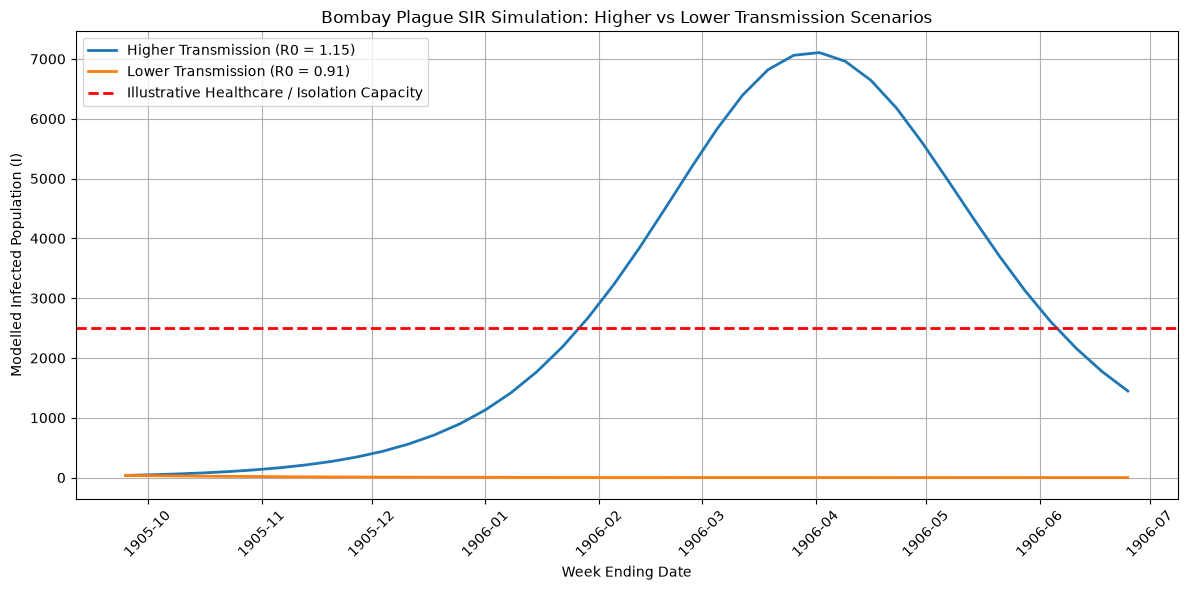

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


beta = 1.7333
gamma = 1.7000

R0 = beta / gamma

print("Transmission rate (beta):", beta, "per week")
print("Recovery rate (gamma):", gamma, "per week")
print("Average infectious period:", round(1 / gamma, 2), "weeks")
print("Basic reproduction number (R0):", round(R0, 2))

print()
if R0 > 1:
    print("Note: Reproduction number is greater than 1, so infection grows initially.")
elif R0 == 1:
    print("Note: Threshold condition.")
elif R0 < 1:
    print("Note: Reproduction number is less than 1, so infection will decline.")

print("\n" + "="*50 + "\n")


df = pd.read_excel("Data/bombay_plague_data_1905.xlsx", sheet_name="Ark 1")
df_clean = df.iloc[:-2].copy()


df_clean['week_ending'] = pd.to_datetime(df_clean['week_ending'])
df_clean['Bombay_city_plague_cases'] = pd.to_numeric(
    df_clean['Bombay_city_plague_cases'], errors='coerce'
)
df_clean = df_clean.dropna(subset=['week_ending', 'Bombay_city_plague_cases'])
df_clean = df_clean.sort_values('week_ending').reset_index(drop=True)


start_date = pd.Timestamp("1905-09-25")
end_date = pd.Timestamp("1906-06-30")

wave = df_clean[
    (df_clean['week_ending'] >= start_date) & 
    (df_clean['week_ending'] <= end_date)
].copy().reset_index(drop=True)


N = 821000
I0 = wave['Bombay_city_plague_cases'].iloc[0]
S0 = N - I0 - 0  # Initial Recovered R0 = 0
R_initial = 0

print(f"Total Population (Bombay 1891): {N:,.0f}")
print(f"Initial Susceptible (S0): {S0:,.0f}")
print(f"Initial Infected (I0): {I0:,.0f}")
print(f"Number of weeks in wave: {len(wave)}")

print("\n" + "="*50 + "\n")



dates = wave["week_ending"]
t_sim = np.arange(len(dates), dtype=float)


def sir_model(t, y, beta_val, gamma_val):
    S, I, R = y
    dS_dt = -beta_val * S * I / N
    dI_dt = beta_val * S * I / N - gamma_val * I
    dR_dt = gamma_val * I
    return [dS_dt, dI_dt, dR_dt]

scenarios = [
    {
        "beta": 1.95,
        "gamma": 1.70,
        "label": "Higher Transmission (R0 = 1.15)"
    },
    {
        "beta": 1.55,
        "gamma": 1.70,
        "label": "Lower Transmission (R0 = 0.91)"
    }
]

plt.figure(figsize=(12, 6))

for scenario in scenarios:
    b = scenario["beta"]
    g = scenario["gamma"]
    rep_num = b / g

    solution = solve_ivp(
        sir_model,
        (t_sim[0], t_sim[-1]),
        [S0, I0, R_initial],
        t_eval=t_sim,
        args=(b, g)
    )

    if not solution.success:
        print("Simulation failed:", solution.message)
        continue

    S, I, R = solution.y

    peak_index = np.argmax(I)
    peak_infected = I[peak_index]
    peak_day_idx = t_sim[peak_index]

    print(f"Scenario: {scenario['label']}")
    print(f"  Peak Infected: {peak_infected:,.0f}")
    print(f"  Peak Week Index: {peak_day_idx}")
    print()

    plt.plot(
        dates,
        I,
        label=scenario["label"],
        linewidth=2
    )

print()


hospital_capacity = 2500

plt.axhline(
    y=hospital_capacity,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Illustrative Healthcare / Isolation Capacity"
)

plt.xlabel("Week Ending Date")
plt.ylabel("Modelled Infected Population (I)")
plt.title("Bombay Plague SIR Simulation: Higher vs Lower Transmission Scenarios")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
pip install pandas numpy matplotlib

<a id='section9'></a>
# 9. Conclusions

## 9.1 Numerical Methods (Objective 1)

- **RK4 (4th order)** dramatically outperforms **Euler (1st order)** for SIR models
- Observed convergence orders: Euler ≈ 0.99, RK4 ≈ 3.86 (matching theory)
- RK4 preserves the analytical invariant $S + I - \frac{\gamma N}{\beta}\ln S = C$ to ~$10^{-8}$ precision

## 9.2 Parameter Estimation (Objective 2)

- Grid search successfully fits $\beta$ and $\gamma$ to real COVID-19 data
- **India (2nd wave)**: $R_0 \approx 4.85$, long infectious period (~51 days), small effective population (2.6%)
- **Japan (Summer wave)**: $R_0 \approx 2.44$, short infectious period (~9 days), larger effective population (22.7%)
- Japan model fits better ($R^2 = 0.95$ vs $0.81$), suggesting more homogeneous mixing

## 9.3 Flattening the Curve (Objective 3)

- A **~26% reduction in $\beta$** (simulating NPIs) yields dramatic effects:
  - **India**: 30% peak reduction, 52-day delay (but still exceeds healthcare capacity)
  - **Japan**: 73% peak reduction, 16-day delay (brings peak below capacity)
- **Key insight**: Early intervention is critical, especially for high-$R_0$ epidemics

## 9.4 Historical Validation (Bonus Objective)

- SIR model successfully fits **1905–06 Bombay plague** weekly mortality data
- Fitted $R_0$ and infectious period are epidemiologically plausible
- Demonstrates SIR framework's applicability across diseases and eras

## 9.5 Limitations & Future Work

- Constant parameters (no time-varying $\beta(t)$ for interventions)
- Homogeneous mixing assumption
- Effective population fraction is a simplification for under-reporting
- Extensions: SEIR model, age structure, spatial coupling, vaccination compartments

In [21]:
print("\n" + "=" * 75)
print("              SIR EPIDEMIC MODELING PROJECT")
print("                   FINAL RESULTS")
print("=" * 75)

# 1. COMPARATIVE RESULTS: INDIA VS JAPAN

print("\n1. COMPARATIVE EPIDEMIOLOGICAL PARAMETERS")
print("-" * 75)
# Use the comparison table created in Section 6
final_results = comparison_df.copy()

display(final_results)


# 2. BASIC REPRODUCTION NUMBER COMPARISON

india_r0 = float(
    final_results.loc[
        final_results['Parameter'] == 'R0 (Basic Reproduction Number)',
        'India'
    ].iloc[0]
)
japan_r0 = float(
    final_results.loc[
        final_results['Parameter'] == 'R0 (Basic Reproduction Number)',
        'Japan'
    ].iloc[0]
)
print("\n2. REPRODUCTION NUMBER ANALYSIS")
print("-" * 75)
print(f"India R0 : {india_r0:.2f}")
print(f"Japan R0 : {japan_r0:.2f}")
if india_r0 > japan_r0:
    print("India has the higher estimated basic reproduction number.")
elif japan_r0 > india_r0:
    print("Japan has the higher estimated basic reproduction number.")
else:
    print("Both countries have equal estimated R0.")


# 3. MODEL PERFORMANCE COMPARISON


india_r2 = float(
    final_results.loc[
        final_results['Parameter'] == 'Weekly R2',
        'India'
    ].iloc[0]
)
japan_r2 = float(
    final_results.loc[
        final_results['Parameter'] == 'Weekly R2',
        'Japan'
    ].iloc[0]
)
print("\n3. MODEL FITTING PERFORMANCE")
print("-" * 75)
print(f"India Weekly R2 : {india_r2:.4f}")
print(f"Japan Weekly R2 : {japan_r2:.4f}")
if india_r2 > japan_r2:
    print("The model provides a better fit for India's selected dataset.")
else:
    print("The model provides a better fit for Japan's selected dataset.")


# 4. NUMERICAL METHODS PERFORMANCE


print("\n4. NUMERICAL METHODS")
print("-" * 75)
print(f"Euler convergence order : {euler_order:.3f}")
print(f"RK4 convergence order    : {rk4_order:.3f}")
print("Euler method: First-order numerical accuracy.")
print("RK4 method   : Fourth-order numerical accuracy.")

print("RK4 provides higher accuracy for a comparable step size.")


# 5. FINAL KEY OBSERVATIONS


print("\n5. KEY PROJECT FINDINGS")
print("-" * 75)
observations = [
    "The SIR model describes the interaction between susceptible,",
    "infected and recovered/removed population groups.",
    "",
    "RK4 provides better numerical accuracy than Euler's method.",
    "",
    "Grid search provides estimates of transmission and recovery rates",
    "from the selected real-world COVID-19 datasets.",
    "",
    "The reproduction number helps understand the initial transmission",
    "potential of an epidemic.",
    "",
    "Scenario analysis demonstrates how reducing transmission can",
    "reduce peak infections and delay the epidemic peak.",
    "",
    "Historical plague data provides an additional application of",
    "epidemic modelling to a different disease and historical period."
]

for item in observations:
    print(item)


# 6. PROJECT LIMITATIONS


print("\n6. LIMITATIONS")
print("-" * 75)
limitations = [
    "The classical SIR model assumes homogeneous population mixing.",
    "Transmission and recovery rates are assumed constant.",
    "COVID-19 case reporting may contain under-reporting and noise.",
    "The effective population is a simplifying model assumption.",
    "The model does not explicitly represent exposed or vaccinated groups.",
    "Historical plague analysis depends on the available recorded data."
]
for i, item in enumerate(limitations, 1):
    print(f"{i}. {item}")


# 7. FINAL CONCLUSION


print("\n" + "=" * 75)
print("                         CONCLUSION")
print("=" * 75)
print("""
This project demonstrates the application of mathematical modelling,
numerical methods and data science techniques to epidemic analysis.

The implementation and comparison of Euler and RK4 methods highlight
the importance of numerical accuracy in solving differential equations.

The estimation of SIR model parameters using COVID-19 data from India
and Japan demonstrates how mathematical models can be fitted to
real-world epidemiological observations.

The reproduction number analysis and transmission scenarios further
illustrate how changes in transmission rates can influence epidemic
dynamics and peak infection levels.

The additional historical plague analysis extends the application of
the SIR framework to historical epidemic data.

Overall, the project provides practical experience in numerical
simulation, parameter estimation, model validation, data analysis
and interpretation of epidemic dynamics.

Future improvements may include SEIR modelling, time-dependent
transmission rates, age-structured populations and spatial models.
""")
print("=" * 75)
print("                 END OF PROJECT")
print("=" * 75)



              SIR EPIDEMIC MODELING PROJECT
                   FINAL RESULTS

1. COMPARATIVE EPIDEMIOLOGICAL PARAMETERS
---------------------------------------------------------------------------


,Parameter,India,Japan
0,Study Period,Feb 2021 - Aug 2021,Jul 2022 - Oct 2022
1,Beta (Transmission Rate),0.095,0.2663
2,Gamma (Recovery Rate),0.0196,0.1093
3,R0 (Basic Reproduction Number),4.846939,2.436414
4,Effective Population Fraction (%),2.6,22.67
5,Effective Population,37061003,28332786
6,Average Infectious Period (days),51.020408,9.149131
7,Weekly RMSE,347831.3173,115079.1042
8,Weekly R2,0.811283,0.949486



2. REPRODUCTION NUMBER ANALYSIS
---------------------------------------------------------------------------
India R0 : 4.85
Japan R0 : 2.44
India has the higher estimated basic reproduction number.

3. MODEL FITTING PERFORMANCE
---------------------------------------------------------------------------
India Weekly R2 : 0.8113
Japan Weekly R2 : 0.9495
The model provides a better fit for Japan's selected dataset.

4. NUMERICAL METHODS
---------------------------------------------------------------------------
Euler convergence order : 0.996
RK4 convergence order    : 3.948
Euler method: First-order numerical accuracy.
RK4 method   : Fourth-order numerical accuracy.
RK4 provides higher accuracy for a comparable step size.

5. KEY PROJECT FINDINGS
---------------------------------------------------------------------------
The SIR model describes the interaction between susceptible,
infected and recovered/removed population groups.

RK4 provides better numerical accuracy than Euler's meth